
# PRCP-1003: Customer Transaction Prediction

## 1. Problem Statement

### Business Understanding

In the banking industry, identifying customers who are likely to perform transactions in the future is important for understanding customer behavior and improving business decision-making.

Banks handle a large volume of customer transactions, and predicting future transaction activity can help them identify potential active customers and make better use of their customer engagement strategies.

The objective of this project is to develop a Machine Learning classification model that predicts whether a customer will make a specific transaction in the future, irrespective of the amount of money transacted.

### Dataset Description

The dataset contains anonymized customer information with the following structure:

- **ID_code:** Unique identifier assigned to each customer.
- **200 Independent Features:** Anonymized numerical features representing customer-related information.
- **Target:** The dependent variable indicating whether a customer will make a transaction in the future.

### Target Variable

The target variable contains two classes:

- **0:** Customer will not make a transaction.
- **1:** Customer will make a transaction.

### Project Objectives

1. Understand the dataset structure and perform data quality analysis.
2. Identify missing values, duplicate records and inconsistencies.
3. Analyze the distribution of the target variable.
4. Perform necessary data preprocessing and feature selection.
5. Develop multiple Machine Learning classification models.
6. Evaluate and compare model performance using appropriate evaluation metrics.
7. Identify the best-performing model for potential production use.
8. Document the challenges encountered and the techniques used to overcome them.

### Expected Outcome

Develop a reliable Machine Learning classification model that can predict whether a customer is likely to perform a future transaction based on the available anonymized features.



## 2. Proposed Solution

### Solution Approach

To solve the customer transaction prediction problem, a supervised Machine Learning classification approach will be implemented.

The dataset contains historical customer records with 200 anonymized independent features and a binary target variable. These features will be used to train classification algorithms to identify patterns associated with future customer transactions.

The project will follow the below implementation approach.

### 1. Data Collection and Loading

- Load the provided customer transaction dataset using Pandas.
- Understand the dataset dimensions, columns and data types.
- Identify the independent variables and target variable.

### 2. Data Quality Analysis

- Check for missing values.
- Identify duplicate records.
- Verify customer ID uniqueness.
- Check for invalid or inconsistent values.
- Analyze the target variable distribution.

### 3. Data Preprocessing

- Remove the ID_code column from model training as it is an identifier.
- Separate independent variables and the target variable.
- Handle missing values, if present.
- Perform appropriate data splitting into training and validation datasets.
- Address class imbalance if identified.

### 4. Feature Engineering and Selection

- Analyze feature distributions and statistical properties.
- Identify highly correlated features.
- Apply suitable feature selection techniques.
- Evaluate feature importance to identify useful predictors.

### 5. Model Development

The following Machine Learning algorithms will be evaluated:

- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- Extra Trees Classifier
- XGBoost Classifier
- LightGBM Classifier
- CatBoost Classifier

### 6. Model Evaluation

The models will be evaluated using the following performance metrics:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC-AUC Score
- Precision-Recall AUC

Special attention will be given to ROC-AUC and Precision-Recall AUC because accuracy alone may not provide a reliable evaluation when the target classes are imbalanced.

### 7. Hyperparameter Tuning

- Identify the promising models based on validation performance.
- Apply suitable hyperparameter optimization techniques.
- Use cross-validation to evaluate model stability.
- Optimize the selected model for better generalization.

### 8. Model Comparison and Production Recommendation

- Compare the performance of all trained models.
- Identify the model that provides the best balance between predictive performance and computational efficiency.
- Recommend the most suitable model for potential production deployment.

### 9. Challenges and Solutions

Document the challenges encountered during the project, the techniques implemented to address them and the reasons for selecting those techniques.

### Final Deliverables

1. Complete Data Analysis Report.
2. Data Preprocessing and Feature Engineering.
3. Multiple Machine Learning Models.
4. Model Performance Comparison Report.
5. Best Model Selection and Production Recommendation.
6. Challenges Faced and Solutions Report.

### Conclusion

The proposed solution aims to develop an effective customer transaction prediction system using supervised Machine Learning techniques. The final model will help identify customers who are likely to make future transactions based on historical patterns in the anonymized dataset.


In [1]:
# Data Manipulation
import pandas as pd

# Numerical Computation
import numpy as np

print("Pandas version:", pd.__version__)
print("Numpy version:",np.__version__)

Pandas version: 2.3.3
Numpy version: 2.3.5


In [2]:
# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# Set default figure size 
plt.rcParams['figure.figsize']=(10,6)

print("Visualization libraries imported successfully!!")

Visualization libraries imported successfully!!


In [4]:
# Data Preprocessing

from sklearn.model_selection import(train_test_split,StratifiedKFold,cross_val_score,RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import(SelectKBest,f_classif,mutual_info_classif)

print("Data preprocessing libraries imported successfully!!!")

Data preprocessing libraries imported successfully!!!


In [7]:
# Classification Algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import(RandomForestClassifier,ExtraTreesClassifier,HistGradientBoostingClassifier)

print("Machine Learning alogorithm imported successfully!!")

Machine Learning alogorithm imported successfully!!


In [8]:
# Model Evaluvation metrics

from sklearn.metrics import(
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        average_precision_score,
        confusion_matrix,
        classification_report,
        ConfusionMatrixDisplay,
        RocCurveDisplay,
        PrecisionRecallDisplay
)

print("Model evaluation libraries imported successfully!!")

Model evaluation libraries imported successfully!!


In [10]:
# Additional libraries

import os # File and directory operations
import time # Measuring model execution time
import joblib # Saving and loading trained ML models
import warnings # Managing unnecessary warning messages
warnings.filterwarnings('ignore')

# Display settings
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",100)
pd.set_option("display.float_format","{:.4f}".format)

print("All additional libraries imported successfully!!!")

All additional libraries imported successfully!!!


In [11]:
# Verify all imports

print("=" * 50)
print("All libraries imported successfully!!!")
print("=" * 50)

All libraries imported successfully!!!



# 4. Data Loading

In this section, the customer transaction dataset is loaded into a Pandas DataFrame for further analysis.

The dataset contains anonymized customer information with 200 independent numerical features, an ID_code column and a binary target variable.

The target variable indicates whether a customer will make a transaction in the future.

The objective of this section is to load the dataset, verify successful loading and understand its dimensions and structure.


In [12]:
# Load the customer transaction dataset

df = pd.read_csv("train(1).csv") # reads the CSV file
                                    # df store data in dataFrame
print("Data set loaded succesfully!!") # prints the result

Data set loaded succesfully!!


In [14]:
# Check the number of rows and columns

print("Number of rows",df.shape[0])
print("Number of columns",df.shape[1])
print("Shape of dataset",df.shape)

Number of rows 200000
Number of columns 202
Shape of dataset (200000, 202)


In [15]:
# Display first five records
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,0.5745,8.7989,14.5691,5.7487,-7.2393,4.2840,30.7133,10.5350,16.2191,2.5791,2.4716,14.3831,13.4325,-5.1488,-0.4073,4.9306,5.9965,-0.3085,12.9041,-3.8766,16.8911,11.1920,10.5785,0.6764,7.8871,4.6667,3.8743,-5.2387,7.3746,11.5767,12.0446,11.6418,-7.0170,5.9226,-14.2136,16.0283,5.3253,12.9194,29.0460,-0.6940,5.1736,-0.7474,14.8322,11.2668,5.3822,2.0183,10.1166,16.1828,4.9590,2.0771,-0.2154,8.6748,9.5319,5.8056,22.4321,5.0109,-4.7010,21.6374,0.5663,5.1999,8.8600,43.1127,18.3816,-2.3440,23.4104,6.5199,12.1983,13.6468,13.8372,1.3675,2.9423,-4.5213,21.4669,9.3225,16.4597,7.9984,-1.7069,-21.4494,6.7806,11.0924,9.9913,14.8421,0.1812,8.9642,16.2572,2.1743,-3.4132,9.4763,13.3102,26.5376,1.4403,14.7100,6.0454,9.5426,17.1554,14.1104,24.3627,2.0323,6.7602,3.9141,-0.4851,2.5240,1.5093,2.5516,15.5752,-13.4221,7.2739,16.0094,9.7268,0.8897,0.7754,4.2218,12.0039,13.8571,-0.7338,-1.9245,15.4462,12.8287,0.3587,9.6508,6.5674,5.1726,3.1345,29.4547,31.4045,2.8279,15.6599,8.3307,-5.6011,19.0614,11.2663,8.6989,8.3694,11.5659,-16.4727,4.0288,17.9244,18.5177,10.7800,9.0056,16.6964,10.4838,1.6573,12.1749,-13.1324,17.6054,11.5423,15.4576,5.3133,3.6159,5.0384,6.6760,12.6644,2.7004,-0.6975,9.5981,5.4879,-4.7645,-8.4254,20.8773,3.1531,18.5618,7.7423,-10.1245,13.7241,-3.5189,1.7202,-8.4051,9.0164,3.0657,14.3691,25.8398,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,8.4135,5.4345,13.7003,13.8275,-15.5849,7.8000,28.5708,3.4287,2.7407,8.5524,3.3716,6.9779,13.8910,-11.7684,-2.5586,5.0464,0.5481,-9.2987,7.8755,1.2859,19.3710,11.3702,0.7399,2.7995,5.8434,10.8160,3.6783,-11.1147,1.8730,9.8775,11.7842,1.2444,-47.3797,7.3718,0.1948,34.4014,25.7037,11.8343,13.2256,-4.1083,6.6885,-8.0946,18.5995,19.3219,7.0118,1.9210,8.8682,8.0109,-7.2417,1.7944,-1.3147,8.1042,1.5365,5.4007,7.9344,5.0220,2.2302,40.5632,0.5134,3.1701,20.1068,7.7841,7.0529,3.2709,23.4822,5.5075,13.7814,2.5462,18.1782,0.3683,-4.8210,-5.4850,13.7867,-13.5901,11.0993,7.9022,12.2301,0.4768,6.8852,8.0905,10.9631,11.7569,-1.2722,24.7876,26.6881,1.8944,0.6939,-13.6950,8.4068,35.4734,1.7093,15.1866,2.6227,7.3412,32.0888,13.9550,13.0858,6.6203,7.1051,5.3523,8.5426,3.6159,4.1569,3.0454,7.8522,-11.5100,7.5109,31.5899,9.5018,8.2736,10.1633,0.1225,12.5942,14.5697

In [16]:
# Display last five recods
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,-0.6209,5.6669,3.7574,-9.5348,13.9860,5.2982,8.2705,14.1527,7.4540,-5.0105,12.0465,8.6349,9.9137,25.1376,1.0914,3.2326,7.7802,13.9939,2.9085,0.1005,4.2369,7.5665,-9.2149,9.5746,1.4012,7.4211,11.0075,7.8080,4.5567,4.9861,9.7471,0.0722,5.9053,8.1743,10.8800,11.1665,4.2600,-2.1296,8.7833,-15.5727,-8.4916,22.1905,12.4110,15.1168,1.6041,6.1868,10.9576,18.7371,15.2986,5.7322,5.1244,9.8225,14.0315,-23.6064,-1.3403,-2.5577,6.3582,-5.4557,5.6063,7.0054,5.0171,-5.0055,28.9502,1.2297,4.4918,19.5568,20.8357,19.2136,17.6422,17.9836,4.0395,14.0761,-5.7878,16.3870,-14.1721,-13.0269,-2.5955,21.4526,15.6163,0.9845,8.2110,-0.8553,-12.1682,6.7779,7.3895,10.5084,15.5057,-0.6812,5.8999,6.1825,3.1038,-1.6930,-18.8473,9.9358,25.3359,1.3647,11.8509,5.0357,6.4630,18.4008,14.3787,19.0369,-0.6364,6.9155,3.6763,3.1460,4.9442,-1.8289,1.3521,34.6265,-0.6869,-5.3781,20.5030,10.9614,4.9677,6.1408,2.2575,12.8757,14.2253,-1.2868,0.2212,16.8661,12.7663,1.2414,7.1304,7.4108,-6.3369,3.0760,24.9796,20.3410,5.3312,23.7116,2.4745,11.2013,17.8165,13.0057,9.5506,5.3589,13.2491,-3.3068,3.6998,2.5927,14.3025,8.1596,7.9609,18.3343,4.3086,1.3546,12.4158,-5.3985,16.3683,10.4522,35.4923,5.5477,7.4244,12.5459,-6.7840,31.1895,2.6529,-11.1867,9.8865,5.4730,-5.3880,-0.4698,24.4025,-5.4493,11.3529,7.7075,-5.0491,13.0756,15.8271,3.3580,-14.3371,10.4421,7.6530,9.4585,22.7783,-4.0305,4.2233,-6.3906,13.5058,-0.4594,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,-3.6797,6.0019,6.5576,-11.8776,14.4131,3.3087,3.5800,14.1597,7.5191,-8.8715,17.9467,17.0237,6.6459,18.2345,0.8982,2.2532,15.4977,13.3282,5.2281,-3.7424,5.5144,5.7148,-13.7470,7.4369,1.3041,12.7552,12.5362,-1.1002,2.4370,6.2631,14.8565,-2.9862,-7.8820,7.1320,11.8869,11.4218,8.9282,-27.2007,14.5962,-19.8502,26.0775,24.3915,12.6910,10.2453,6.8173,4.5666,-9.5685,18.4685,16.9534,7.3660,4.7038,9.4559,6.0037,-10.8728,0.7859,4.7000,7.8077,-1.7926,6.1534,12.9087,5.0398,-0.4247,22.6256,0.7166,0.6533,13.5821,20.3267,25.5380,14.0155,17.3326,4.2046,14.0195,11.4812,17.9954,-18.3549,-3.4537,1.1233,22.3135,1.9795,16.0239,4.7492,0.2446,-39.6406,6.9473,9.9392,11.1977,14.1006,-0.8012,18.8214,32.9827,1.7989,-0.2476,-15.5294,9.5501,11.8548,1.5127,11.3998,4.2304,6.6777,11.3434,14.2993,13.1205,13.3224,7.3143,3.6817,9.7780,4.0491,2.7221,4.4344,3.7648,2.1927,-2.9197,23.0679,12.2112,

In [17]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [18]:
# Generate descriptive statistics
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000,200000.0000
mean,0.1005,10.6799,-1.6276,10.7152,6.7965,11.0783,-5.0653,5.4089,16.5458,0.2842,7.5

In [19]:
# Seperate dependent and independent variables
X = df.drop(columns = ["ID_code","target"])
y = df["target"]

print("Independent Variables Shape:", X.shape)
print("Dependent Variables Shape:",y.shape)

Independent Variables Shape: (200000, 200)
Dependent Variables Shape: (200000,)



# 5. Data Quality Analysis

Data quality analysis is performed to identify potential issues that may affect the accuracy and reliability of Machine Learning models.

In this section, we will examine the dataset for missing values, duplicate records, unique customer identifiers, data types and target variable distribution.

Since the dataset contains 200 anonymized numerical features, these checks will help us understand the quality and consistency of the available data before applying preprocessing techniques.

The following checks will be performed:

1. Missing Value Analysis
2. Duplicate Record Analysis
3. Unique ID Analysis
4. Data Type Validation
5. Target Variable Distribution
6. Class Imbalance Analysis


In [20]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Total missing values:" , missing_values.sum())

# Display columns containing missing values
missing_values[missing_values > 0]

Total missing values: 0


Series([], dtype: int64)

In [21]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum()/len(df)) * 100

missing_df = pd.DataFrame({
        "Missing Values" : missing_values,
        "Missing Percentage" : missing_percentage
})

missing_df.sort_values(
    by = "Missing Percentage",
    ascending = False
).head(10)

,Missing Values,Missing Percentage
ID_code,0,0.0000
var_136,0,0.0000
var_126,0,0.0000
var_127,0,0.0000
var_128,0,0.0000
var_129,0,0.0000
var_130,0,0.0000
var_131,0,0.0000
var_132,0,0.0000
var_133,0,0.0000


In [23]:
# Checking duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicated Records:", duplicate_count)

Total Duplicated Records: 0


In [24]:
# Check number of unique customer ID's

print("Total Customer Records:",len(df))
print("Unique Customer IDs:", df["ID_code"].nunique())
print("ID Date Type:", df["ID_code"].dtype)

Total Customer Records: 200000
Unique Customer IDs: 200000
ID Date Type: object


In [25]:
# Check data type of all columns

print(df.dtypes.value_counts())

float64    200
object       1
int64        1
Name: count, dtype: int64


In [26]:
# Identify non-numerical independent features

non_numeric_features = X.select_dtypes(exclude = ["number"]).columns.tolist()

print("Non-Numerice Features:", non_numeric_features)
                                       

Non-Numerice Features: []


In [28]:
# Count target classes
target_count = df["target"].value_counts().sort_index()
print(target_count)

target
0    179902
1     20098
Name: count, dtype: int64


In [30]:
# Calculate target class percentages
target_percentage = (df["target"].value_counts(normalize = True).sort_index() * 100)
target_summary = pd.DataFrame({'Customer Count' : target_count, "Percentage" : target_percentage})

target_summary

,Customer Count,Percentage
target,,
0,179902,89.9510
1,20098,10.0490


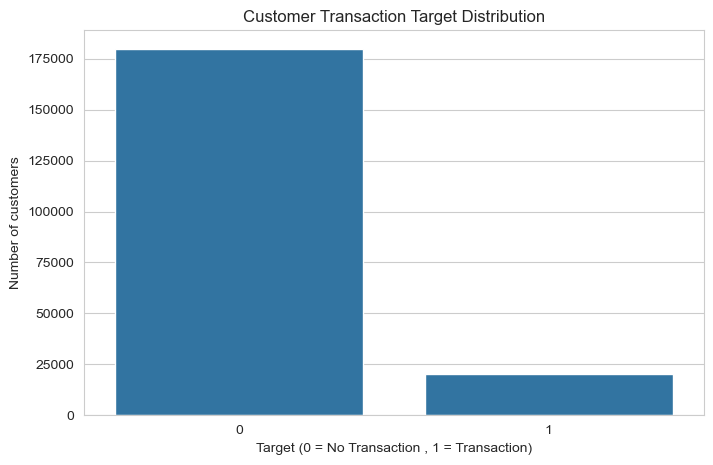

In [33]:
# Visualize target class distribution
plt.figure(figsize = (8,5))
sns.countplot(data=df, x = "target")
plt.title("Customer Transaction Target Distribution")
plt.xlabel("Target (0 = No Transaction , 1 = Transaction)")
plt.ylabel("Number of customers")

plt.show()

In [37]:
# Calculate the class imbalance ration
class_0 = (df["target"] ==0).sum()
class_1 = (df["target"] ==1).sum()
imbalance_ratio = class_0/class_1

print("Class 0:",class_0)
print("Class 1:", class_1)

print("Imbalance Ration:",round(imbalance_ratio,2))

Class 0: 179902
Class 1: 20098
Imbalance Ration: 8.95


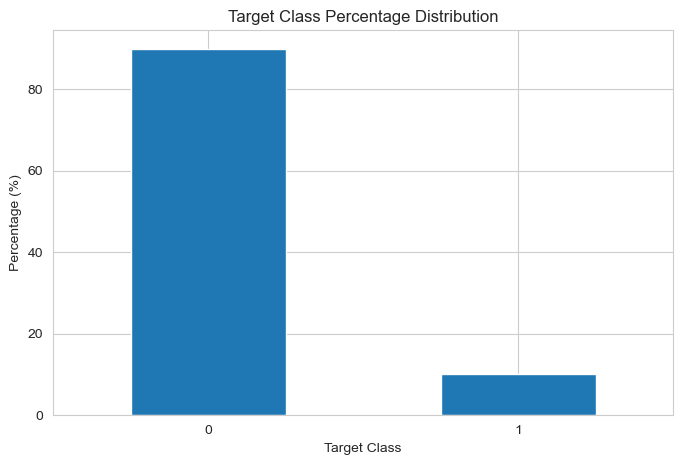

In [39]:
#Plot target percentage distribution

plt.figure(figsize = (8,5))

target_percentage.plot(kind="bar")
plt.title("Target Class Percentage Distribution")
plt.xlabel("Target Class")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)
plt.show()


### 5.8 Data Quality Analysis – Key Findings

Based on the data quality analysis, the following observations were identified:

1. The dataset contains 200,000 customer records and 202 columns.
2. No missing values were identified in the dataset.
3. No duplicate records were found.
4. All 200,000 customer IDs are unique.
5. All 200 independent features are numerical (float64).
6. The ID_code column is an object data type and will be excluded from model training.
7. The target variable contains two classes:
   - Class 0: 179,902 customers (89.951%).
   - Class 1: 20,098 customers (10.049%).

### Identified Challenge: Class Imbalance

The target variable exhibits significant class imbalance, with an imbalance ratio of approximately 8.95:1.

This indicates that the majority class (0) is substantially larger than the minority class (1).

A model trained on this dataset may become biased towards the majority class and fail to identify customers who are likely to perform future transactions.

### Proposed Handling Techniques

- Stratified sampling to maintain class distribution.
- Class weighting to address minority-class misclassification.
- SMOTE as an experimental oversampling technique, if required.
- Evaluation using Precision, Recall, F1-score, ROC-AUC and PR-AUC.

### Conclusion

The dataset is structurally clean, with no missing values or duplicate records. However, class imbalance is an important challenge that must be considered during model development and evaluation.


In [40]:
# Generate statistical summary of independent features

feature_summary = X.describe().T

feature_summary.head(10)

,count,mean,std,min,25%,50%,75%,max
var_0,200000.0000,10.6799,3.0401,0.4084,8.4539,10.5248,12.7582,20.3150
var_1,200000.0000,-1.6276,4.0500,-15.0434,-4.7400,-1.6080,1.3586,10.3768
var_2,200000.0000,10.7152,2.6409,2.1171,8.7225,10.5800,12.5167,19.3530
var_3,200000.0000,6.7965,2.0433,-0.0402,5.2541,6.8250,8.3241,13.1883
var_4,200000.0000,11.0783,1.6231,5.0748,9.8832,11.1082,12.2611,16.6714
var_5,200000.0000,-5.0653,7.8633,-32.5626,-11.2004,-4.8331,0.9248,17.2516
var_6,200000.0000,5.4089,0.8666,2.3473,4.7677,5.3851,6.0030,8.4477
var_7,200000.0000,16.5458,3.4181,5.3497,13.9438,16.4568,19.1029,27.6918
var_8,200000.0000,0.2842,3.3326,-10.5055,-2.3178,0.3937,2.9379,10.1513
var_9,200000.0000,7.5672,1.2351,3.9705,6.6188,7.6296,8.5844,11.1506


In [41]:
# Calculate variance of all independent features

feature_variance = X.var()

# Sort features based on variance
feature_variance = feature_variance.sort_values()

print("Lowest 10 Feature Variances:")
display(feature_variance.head(10))

print("Highest 10 Feature Variances:")
display(feature_variance.tail(10))

Lowest 10 Feature Variances:


var_68    0.0001
var_91    0.0233
var_108   0.0293
var_103   0.0342
var_12    0.0361
var_148   0.0397
var_161   0.0475
var_71    0.0711
var_25    0.0815
var_43    0.0959
dtype: float64

Highest 10 Feature Variances:


var_48    129.6030
var_187   133.9739
var_61    135.0929
var_70    142.8441
var_120   146.9190
var_97    159.8298
var_90    172.9964
var_117   176.8278
var_74    199.1652
var_45    458.1702
dtype: float64

In [42]:
# Identify features with zero variance

constant_features = feature_variance[
    feature_variance == 0
].index.tolist()

print("Number of Constant Features:",
      len(constant_features))

print("Constant Features:",
      constant_features)

Number of Constant Features: 0
Constant Features: []


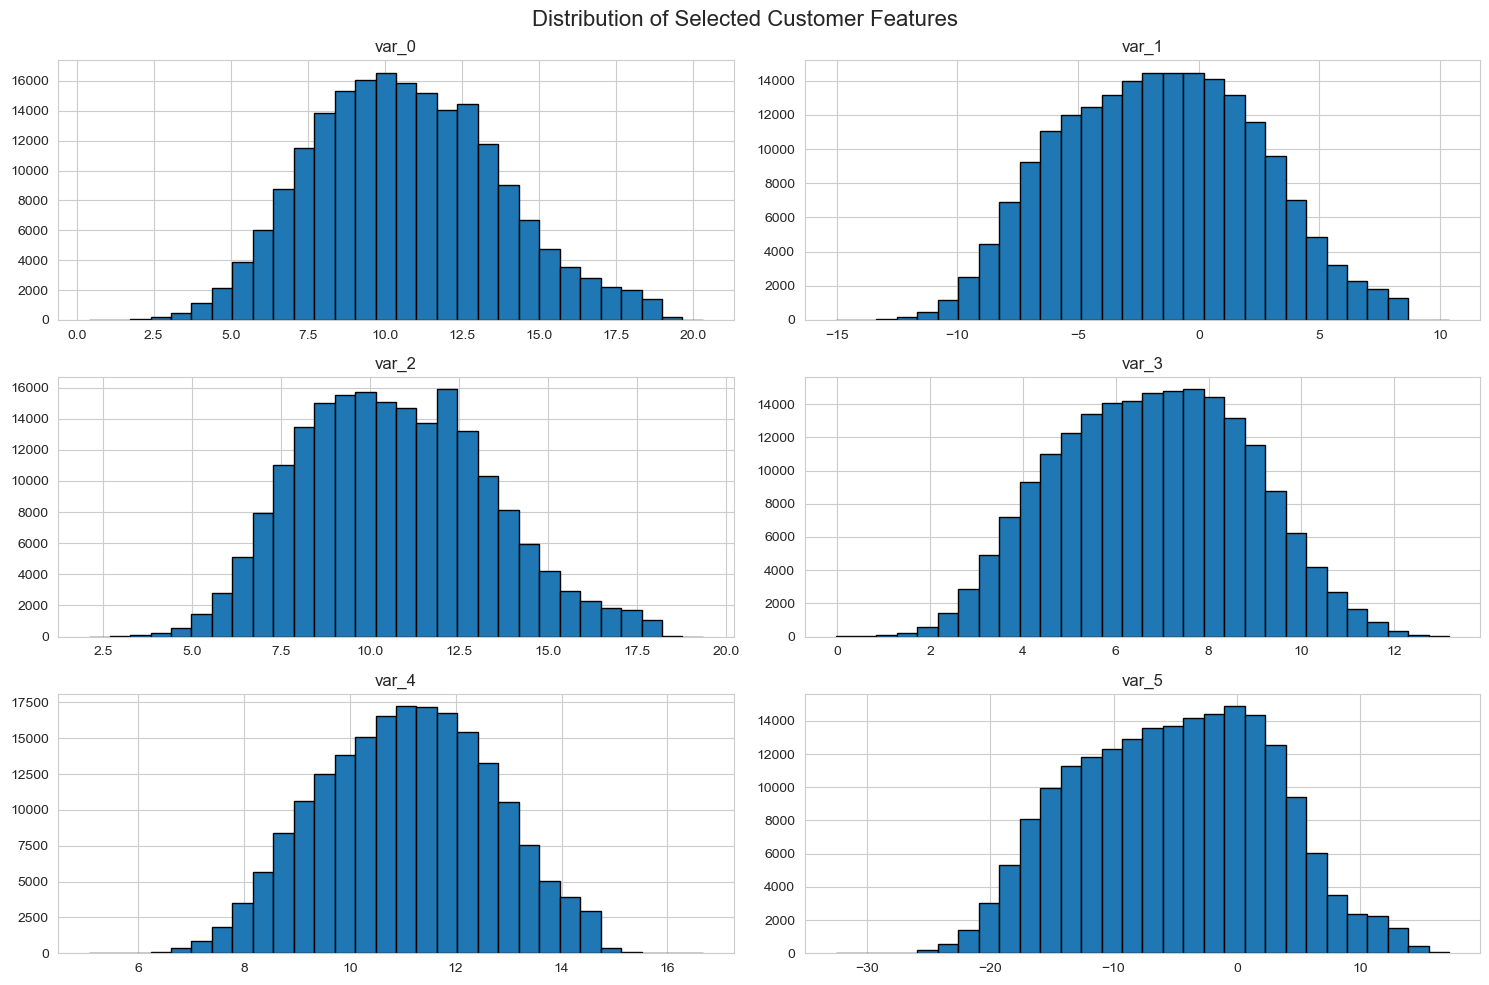

In [43]:
# Select the first 6 features for visualization

selected_features = X.columns[:6]

X[selected_features].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Selected Customer Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [47]:
# Calculate correlation matrix

correlation_matrix = X.corr()

# Display correlation matrix
correlation_matrix.head()
print("Success")

Success


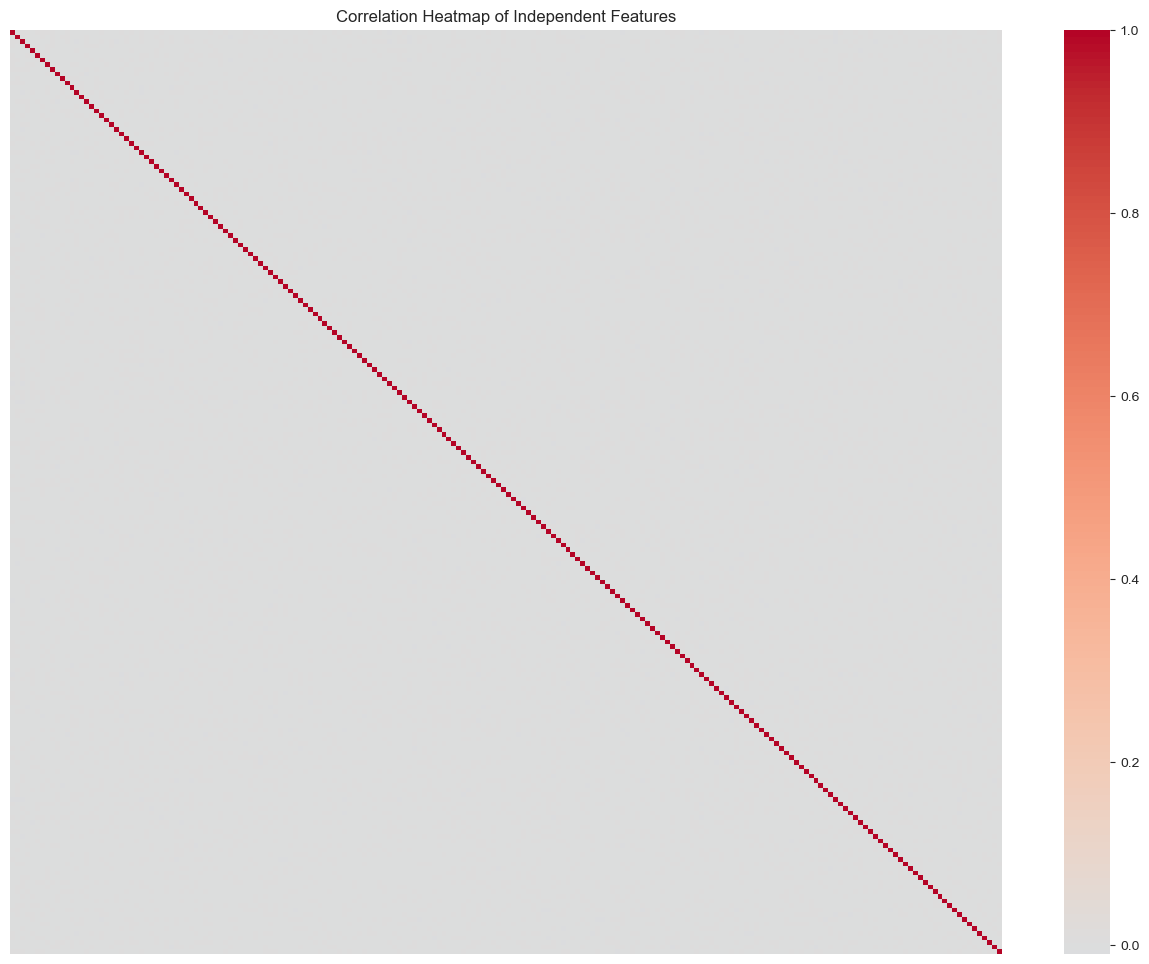

In [48]:
# Correlation heatmap

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title('Correlation Heatmap of Independent Features')

plt.show()

In [49]:
# Extract upper triangular correlation matrix

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Identify highly correlated feature pairs

high_correlation_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

high_correlation_pairs = high_correlation_pairs[
    high_correlation_pairs['Correlation'].abs() > 0.90
]

high_correlation_pairs

,Feature 1,Feature 2,Correlation


In [50]:
from sklearn.feature_selection import f_classif

# Calculate ANOVA F-score and p-values

f_scores, p_values = f_classif(X, y)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'F_Score': f_scores,
    'P_Value': p_values
})

# Sort features by F-score

feature_importance = feature_importance.sort_values(
    by='F_Score',
    ascending=False
)

display(feature_importance.head(15))

,Feature,F_Score,P_Value
81,var_81,1318.1405,0.0000
139,var_139,1103.6038,0.0000
12,var_12,970.4284,0.0000
6,var_6,894.5758,0.0000
110,var_110,829.6822,0.0000
146,var_146,813.3954,0.0000
53,var_53,807.1128,0.0000
26,var_26,782.3467,0.0000
76,var_76,769.6977,0.0000
174,var_174,763.5109,0.0000


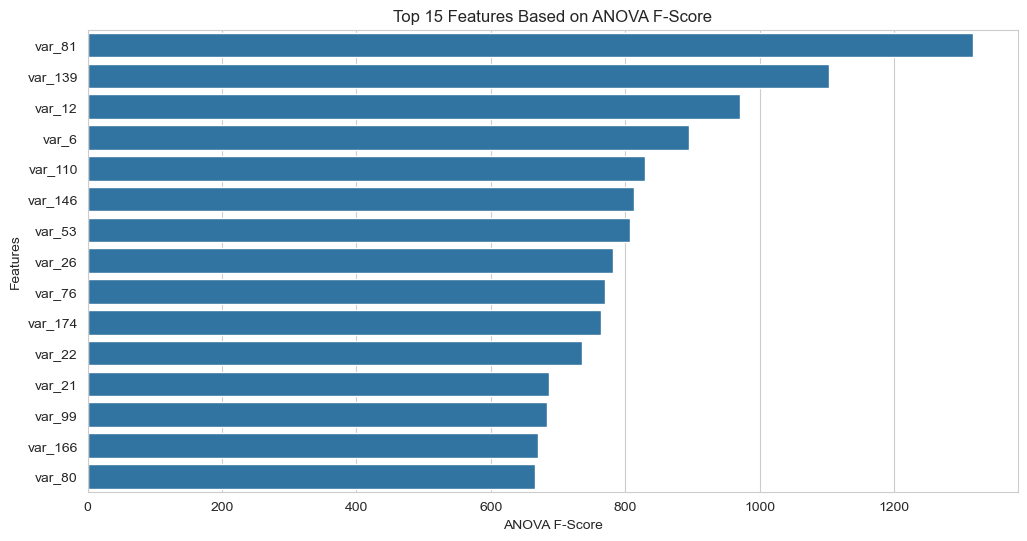

In [51]:
# Plot top 15 features based on ANOVA F-score

top_features = feature_importance.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_features,
    x='F_Score',
    y='Feature'
)

plt.title('Top 15 Features Based on ANOVA F-Score')
plt.xlabel('ANOVA F-Score')
plt.ylabel('Features')

plt.show()


### 6.6 EDA – Key Findings

Based on the exploratory data analysis, the following observations were identified:

1. The selected numerical features exhibit different distribution patterns, with some showing approximately bell-shaped distributions.
2. The feature variances differ significantly.
3. No constant features were identified.
4. var_68 has the lowest variance, while var_45 has the highest variance.
5. No feature pairs were identified with an absolute Pearson correlation greater than 0.90.
6. ANOVA F-score analysis identified var_81, var_139, var_12, var_6 and var_110 as the top five individually associated features with the target variable.

### Conclusion

The dataset contains 200 numerical features with varying statistical distributions and variances.

No constant features or highly correlated feature pairs were identified using the selected thresholds.

The initial ANOVA analysis provides useful insights into the relationship between individual features and the target variable.

All 200 features will initially be retained for baseline model development. Feature selection will be evaluated using training data only to avoid data leakage.



# 7. Data Preprocessing

Data preprocessing is performed to prepare the dataset for Machine Learning model development.

Based on the data quality and exploratory analysis, the dataset contains 200,000 customer records and 200 numerical independent features.

The following preprocessing steps will be performed:

1. Separate independent and dependent variables.
2. Exclude the customer ID column from model training.
3. Check the target variable encoding.
4. Split the dataset into training and validation sets using stratified sampling.
5. Apply feature scaling where required by the selected algorithms.
6. Evaluate class imbalance handling techniques.

Since no missing values or duplicate records were identified, imputation and duplicate removal are not required at this stage.


In [52]:
# Independent Variables

X = df.drop(columns = ["ID_code","target"])

# Dependent variables
y = df["target"]

print("Independent Variables:",X.shape)
print("Dependent Variables:", y.shape)

print("\n Target Classes:")
print(y.unique())

Independent Variables: (200000, 200)
Dependent Variables: (200000,)

 Target Classes:
[0 1]


In [53]:
# Verify target variable values

print("Unique Target Values:", sorted(y.unique()))

print("\nTarget Data Type:", y.dtype)

print("\nTarget Distribution:")
print(y.value_counts())

Unique Target Values: [np.int64(0), np.int64(1)]

Target Data Type: int64

Target Distribution:
target
0    179902
1     20098
Name: count, dtype: int64


In [54]:
# Split data into training and validation sets

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Validation Features:", X_valid.shape)

print("Training Target:", y_train.shape)
print("Validation Target:", y_valid.shape)

Training Features: (160000, 200)
Validation Features: (40000, 200)
Training Target: (160000,)
Validation Target: (40000,)


In [55]:
# Calculate target distribution in training data

print("Training Target Distribution:")
print(
    y_train.value_counts(normalize=True) * 100
)

# Calculate target distribution in validation data

print("\nValidation Target Distribution:")
print(
    y_valid.value_counts(normalize=True) * 100
)

Training Target Distribution:
target
0   89.9513
1   10.0488
Name: proportion, dtype: float64

Validation Target Distribution:
target
0   89.9500
1   10.0500
Name: proportion, dtype: float64


In [56]:
# Initialize StandardScaler

scaler = StandardScaler()

# Fit scaler on training data and transform

X_train_scaled = scaler.fit_transform(X_train)

# Transform validation data using the training scaler

X_valid_scaled = scaler.transform(X_valid)

print("Training Scaled Shape:", X_train_scaled.shape)
print("Validation Scaled Shape:", X_valid_scaled.shape)

Training Scaled Shape: (160000, 200)
Validation Scaled Shape: (40000, 200)


In [57]:
# Final preprocessing verification

print("Missing Values in Training Data:",
      np.isnan(X_train).sum().sum())

print("Missing Values in Validation Data:",
      np.isnan(X_valid).sum().sum())

print("\nTraining Data Shape:", X_train.shape)
print("Validation Data Shape:", X_valid.shape)

print("\nPreprocessing completed successfully!")

Missing Values in Training Data: 0
Missing Values in Validation Data: 0

Training Data Shape: (160000, 200)
Validation Data Shape: (40000, 200)

Preprocessing completed successfully!



# 8. Machine Learning Model Building

In this section, multiple supervised Machine Learning classification algorithms will be developed to predict whether a customer is likely to perform a future transaction.

The dataset contains 200 numerical independent features and a binary target variable.

Since the target variable is imbalanced, model evaluation will focus on identifying customers belonging to the minority class (target = 1), in addition to overall predictive performance.

The following algorithms will be evaluated:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Extra Trees Classifier
5. XGBoost Classifier
6. LightGBM Classifier
7. CatBoost Classifier

The models will initially be trained using the original class distribution. Their performance will be compared using appropriate classification metrics.

The objective is to identify a model that provides a good balance between predictive performance, generalization and computational efficiency.


In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import time

# Store model performance results
model_results = []

def evaluate_model(model_name, y_true, y_pred, y_prob, training_time):

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1_Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_prob),
        'PR_AUC': average_precision_score(y_true, y_prob),
        'Training_Time': training_time
    }

    model_results.append(results)

    return results

In [61]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Initialize the model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model

start_time = time.time()

lr_model.fit(X_train_scaled, y_train)

lr_training_time = time.time() - start_time

# Make predictions

lr_predictions = lr_model.predict(X_valid_scaled)

# Predict probabilities

lr_probabilities = lr_model.predict_proba(X_valid_scaled)[:, 1]

# Evaluate the model

lr_results = evaluate_model(
    'Logistic Regression',
    y_valid,
    lr_predictions,
    lr_probabilities,
    lr_training_time
)

print("Logistic Regression Results:")
print(lr_results)

Logistic Regression Results:
{'Model': 'Logistic Regression', 'Accuracy': 0.9134, 'Precision': 0.682175622542595, 'Recall': 0.258955223880597, 'F1_Score': 0.3754056978002164, 'ROC_AUC': 0.8598618773835104, 'PR_AUC': 0.5004389990941253, 'Training_Time': 1.3862557411193848}


In [62]:
# Import Decision Tree

from sklearn.tree import DecisionTreeClassifier

# Initialize the model

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10
)

# Train the model

start_time = time.time()

dt_model.fit(X_train, y_train)

dt_training_time = time.time() - start_time

# Make predictions

dt_predictions = dt_model.predict(X_valid)

# Predict probabilities

dt_probabilities = dt_model.predict_proba(X_valid)[:, 1]

# Evaluate the model

dt_results = evaluate_model(
    'Decision Tree',
    y_valid,
    dt_predictions,
    dt_probabilities,
    dt_training_time
)

print("Decision Tree Results:")
print(dt_results)

Decision Tree Results:
{'Model': 'Decision Tree', 'Accuracy': 0.8957, 'Precision': 0.3707482993197279, 'Recall': 0.054228855721393035, 'F1_Score': 0.09461805555555555, 'ROC_AUC': 0.6622166163346692, 'PR_AUC': 0.18953255463331203, 'Training_Time': 72.2632999420166}


In [63]:
# Display initial model comparison

model_comparison = pd.DataFrame(model_results)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633


In [64]:
# Display initial model comparison

model_comparison = pd.DataFrame(model_results)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633


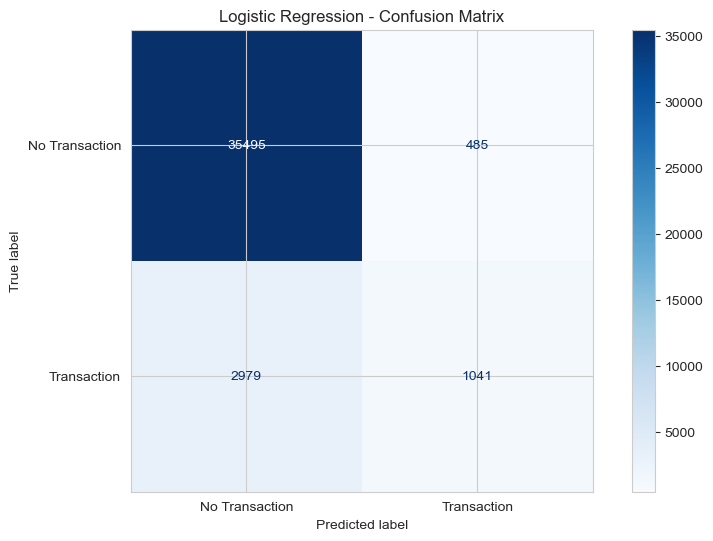

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    lr_predictions,
    display_labels=['No Transaction', 'Transaction'],
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()


### 8.8 Baseline Model Evaluation – Findings

Two classification algorithms were initially developed and evaluated.

**1. Logistic Regression**

- Accuracy: 91.34%
- Precision: 68.22%
- Recall: 25.90%
- F1-score: 37.54%
- ROC-AUC: 0.8599
- PR-AUC: 0.5004
- Training time: 1.39 seconds

Logistic Regression demonstrated better classification performance compared with the Decision Tree baseline.

However, its recall of 25.90% indicates that it fails to identify a significant proportion of actual transacting customers at the default probability threshold of 0.5.

**2. Decision Tree Classifier**

- Accuracy: 89.57%
- Precision: 37.07%
- Recall: 5.42%
- F1-score: 9.46%
- ROC-AUC: 0.6622
- PR-AUC: 0.1895
- Training time: 72.26 seconds

The Decision Tree demonstrated weaker predictive performance and required significantly more training time.

### Baseline Model Conclusion

Logistic Regression outperformed Decision Tree across the evaluated metrics.

However, both models require further optimization, particularly in identifying minority-class customers.

Additional ensemble algorithms and class imbalance handling techniques will be evaluated before selecting the final model.


In [66]:
# Import Random Forest

from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Train model

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

# Predictions

rf_predictions = rf_model.predict(X_valid)

rf_probabilities = rf_model.predict_proba(X_valid)[:, 1]

# Evaluate model

rf_results = evaluate_model(
    'Random Forest',
    y_valid,
    rf_predictions,
    rf_probabilities,
    rf_training_time
)

print("Random Forest Results:")
print(rf_results)

Random Forest Results:
{'Model': 'Random Forest', 'Accuracy': 0.8995, 'Precision': 0.0, 'Recall': 0.0, 'F1_Score': 0.0, 'ROC_AUC': 0.8193547755939591, 'PR_AUC': 0.41325490907884566, 'Training_Time': 160.88431572914124}


In [67]:
# Import Random Forest

from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Train model

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

# Predictions

rf_predictions = rf_model.predict(X_valid)

rf_probabilities = rf_model.predict_proba(X_valid)[:, 1]

# Evaluate model

rf_results = evaluate_model(
    'Random Forest',
    y_valid,
    rf_predictions,
    rf_probabilities,
    rf_training_time
)

print("Random Forest Results:")
print(rf_results)

Random Forest Results:
{'Model': 'Random Forest', 'Accuracy': 0.8995, 'Precision': 0.0, 'Recall': 0.0, 'F1_Score': 0.0, 'ROC_AUC': 0.8193547755939591, 'PR_AUC': 0.41325490907884566, 'Training_Time': 150.07013607025146}


In [68]:
# Compare all four models

model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    by='ROC_AUC',
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,160.8843
2,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,150.0701
3,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633


In [69]:
# Check predicted probability distribution

print("Minimum Probability:",
      rf_probabilities.min())

print("Maximum Probability:",
      rf_probabilities.max())

print("Mean Probability:",
      rf_probabilities.mean())

print("\nProbability Percentiles:")

print(
    np.percentile(
        rf_probabilities,
        [25, 50, 75, 90, 95, 99]
    )
)

Minimum Probability: 0.0392584766607138
Maximum Probability: 0.47073650201345674
Mean Probability: 0.09951427098821311

Probability Percentiles:
[0.06572745 0.08811675 0.12123592 0.16204852 0.19019061 0.25147708]


In [70]:
# Check prediction distribution

print("Random Forest Prediction Counts:")

print(pd.Series(rf_predictions).value_counts())

print("\nActual Validation Distribution:")

print(y_valid.value_counts())


Random Forest Prediction Counts:
0    40000
Name: count, dtype: int64

Actual Validation Distribution:
target
0    35980
1     4020
Name: count, dtype: int64


In [71]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10]

for threshold in thresholds:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Predicted_Positive': predictions.sum(),
        'Precision': precision_score(
            y_valid, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_valid, predictions, zero_division=0
        ),
        'F1_Score': f1_score(
            y_valid, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison

,Threshold,Predicted_Positive,Precision,Recall,F1_Score
0,0.5000,0,0.0000,0.0000,0.0000
1,0.4000,2,1.0000,0.0005,0.0010
2,0.3000,93,0.9032,0.0209,0.0408
3,0.2000,1539,0.5893,0.2256,0.3263
4,0.1000,15746,0.2086,0.8172,0.3324


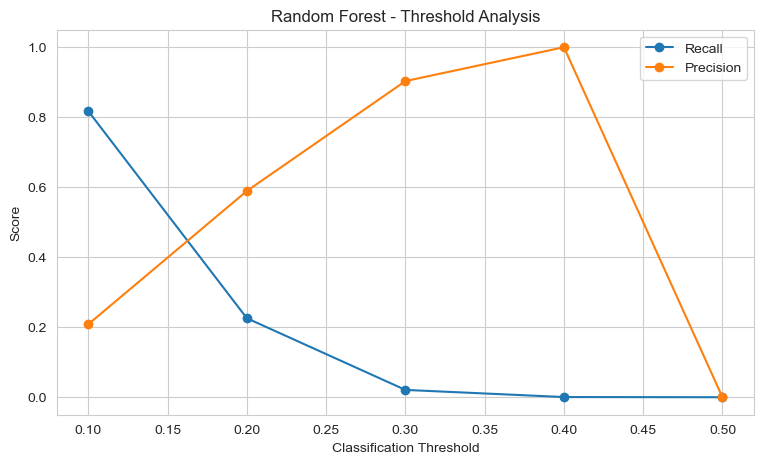

In [72]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_comparison['Threshold'],
    threshold_comparison['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_comparison['Threshold'],
    threshold_comparison['Precision'],
    marker='o',
    label='Precision'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Random Forest - Threshold Analysis')

plt.legend()
plt.grid(True)

plt.show()


### 8.10 Random Forest – Classification Threshold Analysis

The Random Forest model initially predicted all validation records as class 0 at the default threshold of 0.5.

The maximum predicted transaction probability was 0.4707, explaining why no positive predictions were generated.

To investigate model performance, different classification thresholds were evaluated.

#### Key Findings

- At threshold 0.50, recall was 0%.
- At threshold 0.30, precision was 90.32%, but recall was only 2.09%.
- At threshold 0.20, precision improved to 58.93%, with recall of 22.56%.
- At threshold 0.10, recall increased to 81.72%, while precision decreased to 20.86%.

#### Conclusion

The experiment demonstrates that classification threshold selection significantly affects minority-class prediction performance.

A lower threshold improves the identification of potential transacting customers but increases false-positive predictions.

The threshold will be selected based on business requirements and further validation. The current experiment is exploratory and will not be treated as final production threshold selection.


In [75]:
# Import Extra Trees Classifier

from sklearn.ensemble import ExtraTreesClassifier

# Initialize Extra Trees model

et_model = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Train the model

start_time = time.time()

et_model.fit(X_train, y_train)

et_training_time = time.time() - start_time

print("Extra Trees Training Time:",
      round(et_training_time, 2), "seconds")

Extra Trees Training Time: 84.31 seconds


In [77]:
# Predict customer transaction classes

et_predictions = et_model.predict(X_valid)

# Predict transaction probabilities

et_probabilities = et_model.predict_proba(X_valid)[:, 1]

In [78]:
et_results = evaluate_model(
    'Extra Trees',
    y_valid,
    et_predictions,
    et_probabilities,
    et_training_time
)

print("Extra Trees Results:")
print(et_results)

Extra Trees Results:
{'Model': 'Extra Trees', 'Accuracy': 0.8995, 'Precision': 0.0, 'Recall': 0.0, 'F1_Score': 0.0, 'ROC_AUC': 0.8318168848641728, 'PR_AUC': 0.4419807399917289, 'Training_Time': 84.305415391922}


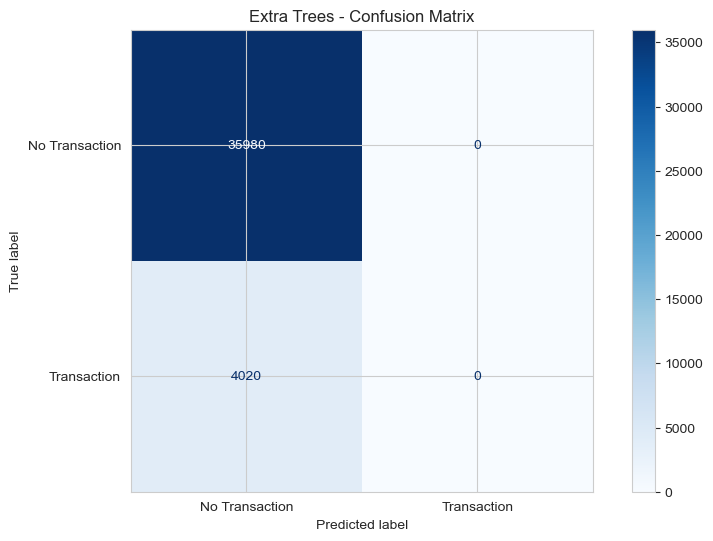

In [79]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    et_predictions,
    display_labels=['No Transaction', 'Transaction'],
    cmap='Blues'
)

plt.title('Extra Trees - Confusion Matrix')
plt.show()

In [80]:
model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.drop_duplicates(
    subset=['Model'],
    keep='last'
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633
2,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,150.0701
3,Extra Trees,0.8995,0.0000,0.0000,0.0000,0.8318,0.4420,84.3054



### 8.11 Extra Trees – Model Evaluation Findings

The Extra Trees Classifier was trained using 100 randomized decision trees.

#### Performance Results

- Accuracy: 89.95%
- Precision: 0.00
- Recall: 0.00
- F1-score: 0.00
- ROC-AUC: 0.8318
- PR-AUC: 0.4420
- Training Time: 84.31 seconds

#### Observations

The model predicted all validation records as class 0 at the default classification threshold of 0.5.

Although the model achieved 89.95% accuracy, it failed to identify any customers belonging to the minority class.

The ROC-AUC and PR-AUC scores indicate that the model has some ability to distinguish potential transacting customers based on predicted probabilities.

#### Conclusion

Extra Trees demonstrated better ranking performance than Random Forest and Decision Tree based on ROC-AUC and PR-AUC.

However, its default classification performance is inadequate for the banking business objective.

Threshold optimization and class imbalance handling will be investigated in subsequent experiments.


In [81]:
try:
    import xgboost as xgb
    print("XGBoost Version:", xgb.__version__)
    print("XGBoost is available!")

except ImportError:
    print("XGBoost is not installed.")

XGBoost Version: 3.2.0
XGBoost is available!


In [82]:
from xgboost import XGBClassifier

# Initialize XGBoost

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# Train model

start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start_time

print(
    "XGBoost Training Time:",
    round(xgb_training_time, 2),
    "seconds"
)

XGBoost Training Time: 80.32 seconds


In [86]:
# Predict classes

xgb_predictions = xgb_model.predict(X_valid)

# Predict probabilities

xgb_probabilities = xgb_model.predict_proba(X_valid)[:, 1]

In [87]:
xgb_results = evaluate_model(
    'XGBoost',
    y_valid,
    xgb_predictions,
    xgb_probabilities,
    xgb_training_time
)

print("XGBoost Results:")
print(xgb_results)

XGBoost Results:
{'Model': 'XGBoost', 'Accuracy': 0.90515, 'Precision': 0.8791946308724832, 'Recall': 0.06517412935323383, 'F1_Score': 0.12135247799907364, 'ROC_AUC': 0.857960109126408, 'PR_AUC': 0.4964770693726699, 'Training_Time': 80.32139039039612}


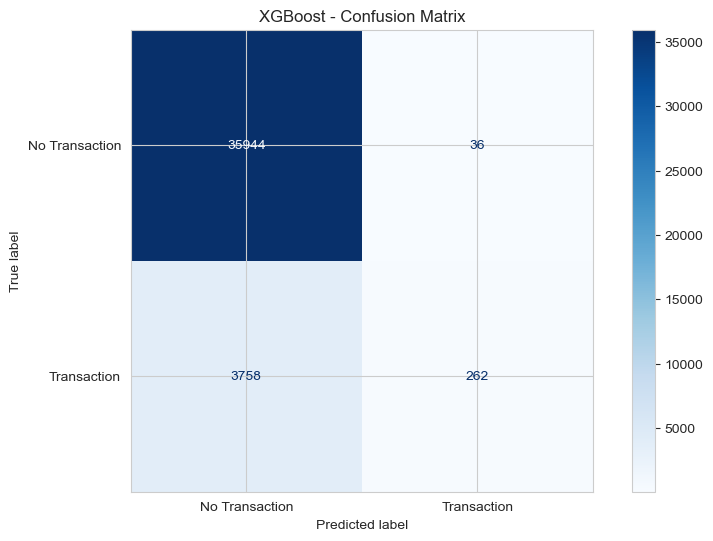

In [88]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    xgb_predictions,
    display_labels=[
        'No Transaction',
        'Transaction'
    ],
    cmap='Blues'
)

plt.title('XGBoost - Confusion Matrix')
plt.show()

In [89]:
model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.drop_duplicates(
    subset=['Model'],
    keep='last'
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633
2,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,150.0701
3,Extra Trees,0.8995,0.0000,0.0000,0.0000,0.8318,0.4420,84.3054
4,XGBoost,0.9052,0.8792,0.0652,0.1214,0.8580,0.4965,80.3214



### 8.12 XGBoost – Model Evaluation Findings

XGBoost was implemented using gradient boosting with 200 estimators and a learning rate of 0.05.

#### Performance Results

- Accuracy: 90.52%
- Precision: 87.92%
- Recall: 6.52%
- F1-score: 12.14%
- ROC-AUC: 0.8580
- PR-AUC: 0.4965
- Training Time: 80.32 seconds

#### Observations

1. XGBoost achieved the highest precision among the five models evaluated so far.
2. The model correctly identified 262 out of 4,020 actual transacting customers.
3. It produced only 36 false positive predictions.
4. Recall remained low at 6.52%, indicating that the model missed most actual transacting customers.
5. ROC-AUC and PR-AUC indicate good probability-ranking performance compared with the other baseline models.

#### Conclusion

XGBoost demonstrates strong precision but insufficient recall at the default classification threshold.

It will be retained for further experimentation with class weighting and classification threshold optimization.


In [90]:
try:
    import lightgbm as lgb

    print("LightGBM Version:", lgb.__version__)
    print("LightGBM is available!")

except ImportError:
    print("LightGBM is not installed.")

LightGBM is not installed.


In [91]:
%pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------ --------- 1.0/1.4 MB 13.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 8.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [93]:
from lightgbm import LGBMClassifier

# Initialize LightGBM

lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train model

start_time = time.time()

lgbm_model.fit(X_train, y_train)

lgbm_training_time = time.time() - start_time

print(
    "LightGBM Training Time:",
    round(lgbm_training_time, 2),
    "seconds"
)

LightGBM Training Time: 35.45 seconds


In [95]:
# Predict customer transaction classes

lgbm_predictions = lgbm_model.predict(X_valid)

# Predict transaction probabilities

lgbm_probabilities = lgbm_model.predict_proba(X_valid)[:, 1]

In [96]:
lgbm_results = evaluate_model(
    'LightGBM',
    y_valid,
    lgbm_predictions,
    lgbm_probabilities,
    lgbm_training_time
)

print("LightGBM Results:")
print(lgbm_results)

LightGBM Results:
{'Model': 'LightGBM', 'Accuracy': 0.906525, 'Precision': 0.8870523415977961, 'Recall': 0.08009950248756219, 'F1_Score': 0.14693132557608943, 'ROC_AUC': 0.8703450438192583, 'PR_AUC': 0.5300818521515105, 'Training_Time': 35.45074653625488}


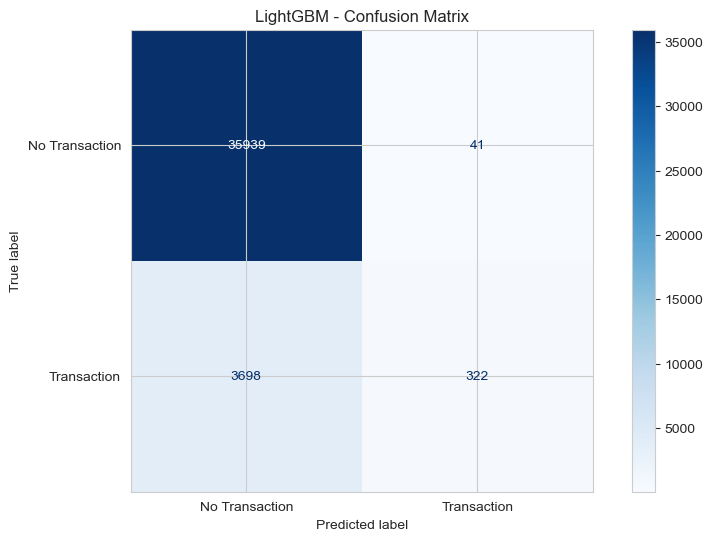

In [97]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    lgbm_predictions,
    display_labels=[
        'No Transaction',
        'Transaction'
    ],
    cmap='Blues'
)

plt.title('LightGBM - Confusion Matrix')
plt.show()

In [98]:
model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.drop_duplicates(
    subset=['Model'],
    keep='last'
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633
2,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,150.0701
3,Extra Trees,0.8995,0.0000,0.0000,0.0000,0.8318,0.4420,84.3054
4,XGBoost,0.9052,0.8792,0.0652,0.1214,0.8580,0.4965,80.3214
5,LightGBM,0.9065,0.8871,0.0801,0.1469,0.8703,0.5301,35.4507



### 8.13 LightGBM – Model Evaluation Findings

LightGBM was implemented using 200 estimators and a learning rate of 0.05.

#### Performance Results

- Accuracy: 90.65%
- Precision: 88.71%
- Recall: 8.01%
- F1-score: 14.69%
- ROC-AUC: 0.8703
- PR-AUC: 0.5301
- Training Time: 35.45 seconds

#### Observations

1. LightGBM achieved the highest ROC-AUC score among the six evaluated models.
2. It achieved the highest PR-AUC score among the six evaluated models.
3. It demonstrated the highest precision at the default threshold.
4. The model correctly identified 322 out of 4,020 actual transacting customers.
5. The model achieved comparatively low training time.

#### Identified Challenge

Despite its strong ranking performance, LightGBM achieved only 8.01% recall at the default classification threshold.

This indicates that the model is missing a significant proportion of actual transacting customers.

#### Conclusion

LightGBM is currently the leading model based on ROC-AUC, PR-AUC and training efficiency.

Further experimentation with class imbalance handling and threshold optimization is required to improve minority-class identification.


In [99]:
try:
    import catboost

    print("CatBoost Version:", catboost.__version__)
    print("CatBoost is available!")

except ImportError:
    print("CatBoost is not installed.")

CatBoost is not installed.


In [100]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/100.2 MB 3.3 MB/s eta 0:00:31
   ---------------------------------------- 1.0/100.2 MB 3.9 MB/s eta 0:00:26
    --------------------------------------- 1.6/100.2 MB 2.7 MB/s eta 0:00:36
    --------------------------------------- 2.1/100.2 MB 3.1 MB/s eta 0:00:32
   - -------------------------------------- 2.9/100.2 MB 2.9 MB/s eta 0:00:34
   - -------------------------------------- 3.1/100.2 MB 3.0 MB/s eta 0:00:33
   - -------------------------------------- 4.2/100.2 MB 2.9 MB/s eta 0:00:34
   - -------------------------------------- 4.5/100.2 MB 2.5 MB/s eta 0:00:38
   -- ------------------------------------- 5.2/100.2 MB 2.8 MB/s eta 0:00:34
   -- ------------------------------------- 6.3/100.2 MB 2.9 MB/s eta 0:00:33
   -- ------------------------------------- 7.3/100.2 MB 3.0 MB/s eta 0:00:31
   -- ------------------------------------- 7.3/100.2 MB 3.0 MB/s eta 0

In [101]:
from catboost import CatBoostClassifier

# Initialize CatBoost

cat_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=False,
    thread_count=-1
)

# Train model

start_time = time.time()

cat_model.fit(X_train, y_train)

cat_training_time = time.time() - start_time

print(
    "CatBoost Training Time:",
    round(cat_training_time, 2),
    "seconds"
)

CatBoost Training Time: 68.64 seconds


In [103]:
# Predict customer transaction classes

cat_predictions = cat_model.predict(X_valid)

# Predict transaction probabilities

cat_probabilities = cat_model.predict_proba(X_valid)[:, 1]

In [104]:
cat_results = evaluate_model(
    'CatBoost',
    y_valid,
    cat_predictions,
    cat_probabilities,
    cat_training_time
)

print("CatBoost Results:")
print(cat_results)

CatBoost Results:
{'Model': 'CatBoost', 'Accuracy': 0.90325, 'Precision': 0.8787878787878788, 'Recall': 0.04328358208955224, 'F1_Score': 0.08250355618776671, 'ROC_AUC': 0.8553561887615839, 'PR_AUC': 0.49225915911893514, 'Training_Time': 68.63695478439331}


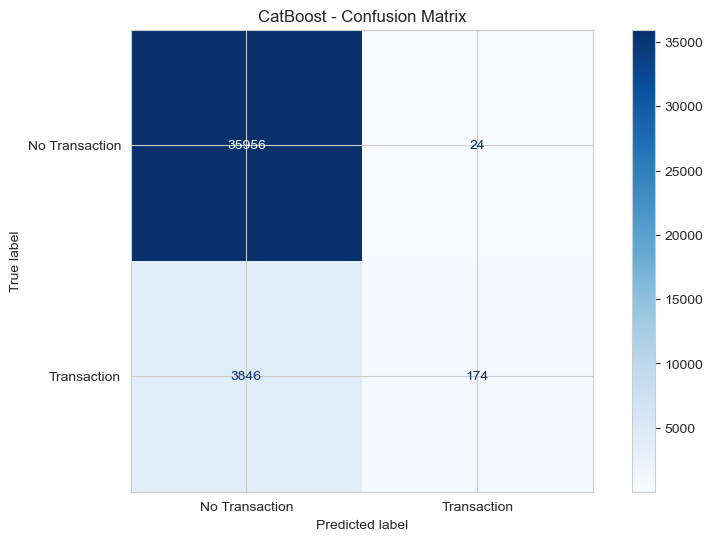

In [105]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    cat_predictions,
    display_labels=[
        'No Transaction',
        'Transaction'
    ],
    cmap='Blues'
)

plt.title('CatBoost - Confusion Matrix')
plt.show()

In [106]:
model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.drop_duplicates(
    subset=['Model'],
    keep='last'
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
1,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633
2,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,150.0701
3,Extra Trees,0.8995,0.0000,0.0000,0.0000,0.8318,0.4420,84.3054
4,XGBoost,0.9052,0.8792,0.0652,0.1214,0.8580,0.4965,80.3214
5,LightGBM,0.9065,0.8871,0.0801,0.1469,0.8703,0.5301,35.4507
6,CatBoost,0.9032,0.8788,0.0433,0.0825,0.8554,0.4923,68.6370



### 8.14 CatBoost – Model Evaluation Findings

CatBoost was implemented using 200 iterations, a tree depth of 6 and a learning rate of 0.05.

#### Performance Results

- Accuracy: 90.33%
- Precision: 87.88%
- Recall: 4.33%
- F1-score: 8.25%
- ROC-AUC: 0.8554
- PR-AUC: 0.4923
- Training Time: 68.64 seconds

#### Observations

1. CatBoost achieved high precision of 87.88%.
2. It correctly identified 174 out of 4,020 actual transacting customers.
3. It generated only 24 false positive predictions.
4. Recall remained low at 4.33%.
5. The model demonstrated good probability-ranking performance but poor minority-class identification at the default threshold.

#### Conclusion

CatBoost provides highly precise predictions at the default threshold but fails to identify a sufficient number of potential transacting customers.

Further optimization is required before considering it for production.


In [107]:
# Create consolidated model comparison

model_comparison = pd.DataFrame(model_results)

# Remove duplicate model entries
model_comparison = model_comparison.drop_duplicates(
    subset=['Model'],
    keep='last'
)

# Sort by PR-AUC
model_comparison = model_comparison.sort_values(
    by='PR_AUC',
    ascending=False
).reset_index(drop=True)

# Display selected columns
display(
    model_comparison[
        [
            'Model',
            'Accuracy',
            'Precision',
            'Recall',
            'F1_Score',
            'ROC_AUC',
            'PR_AUC',
            'Training_Time'
        ]
    ].round(4)
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,LightGBM,0.9065,0.8871,0.0801,0.1469,0.8703,0.5301,35.4507
1,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,0.5004,1.3863
2,XGBoost,0.9052,0.8792,0.0652,0.1214,0.8580,0.4965,80.3214
3,CatBoost,0.9032,0.8788,0.0433,0.0825,0.8554,0.4923,68.6370
4,Extra Trees,0.8995,0.0000,0.0000,0.0000,0.8318,0.4420,84.3054
5,Random Forest,0.8995,0.0000,0.0000,0.0000,0.8194,0.4133,150.0701
6,Decision Tree,0.8957,0.3707,0.0542,0.0946,0.6622,0.1895,72.2633


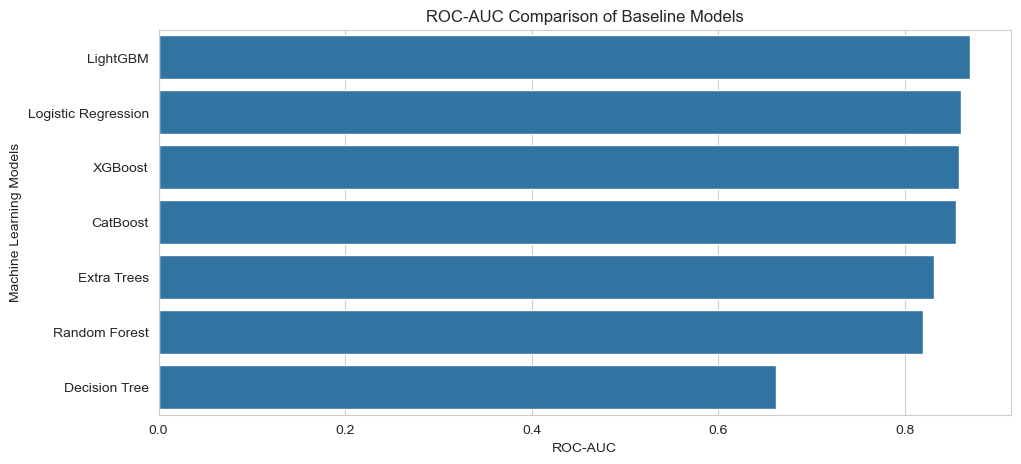

In [108]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=model_comparison,
    x='ROC_AUC',
    y='Model'
)

plt.title('ROC-AUC Comparison of Baseline Models')
plt.xlabel('ROC-AUC')
plt.ylabel('Machine Learning Models')

plt.show()

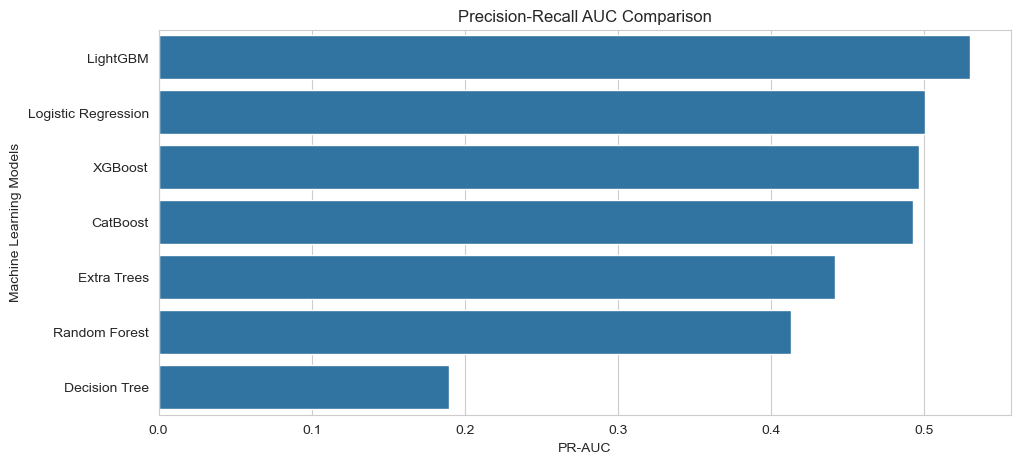

In [109]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=model_comparison,
    x='PR_AUC',
    y='Model'
)

plt.title('Precision-Recall AUC Comparison')
plt.xlabel('PR-AUC')
plt.ylabel('Machine Learning Models')

plt.show()

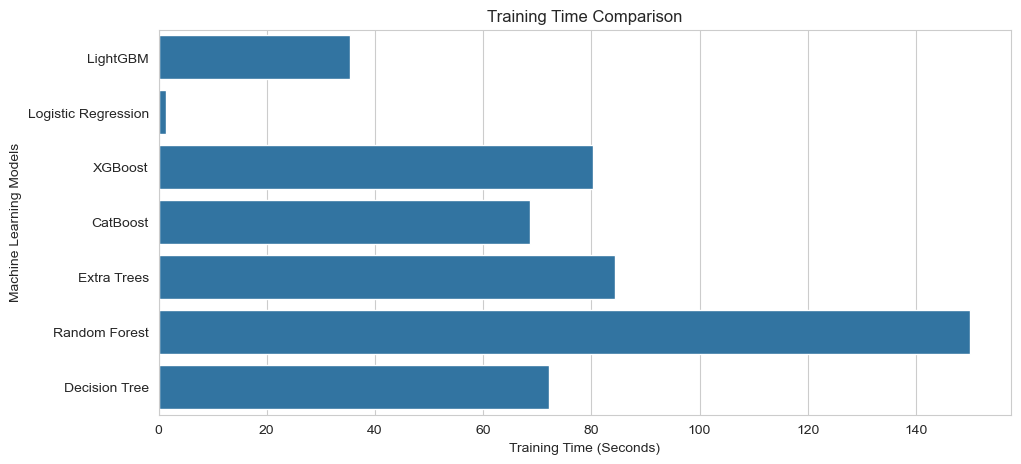

In [110]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=model_comparison,
    x='Training_Time',
    y='Model'
)

plt.title('Training Time Comparison')
plt.xlabel('Training Time (Seconds)')
plt.ylabel('Machine Learning Models')

plt.show()


# 9. Handling Class Imbalance

The dataset contains a significant imbalance in the target variable.

- Class 0: 179,902 records (89.95%).
- Class 1: 20,098 records (10.05%).

The majority class is approximately 8.95 times larger than the minority class.

During baseline model development, several algorithms demonstrated high accuracy and precision but low recall for the minority class.

This indicates that the models are biased towards predicting the majority class at the default classification threshold.

To address this challenge, different class imbalance handling techniques will be investigated:

1. Class Weight Adjustment
2. SMOTE (Synthetic Minority Oversampling Technique)
3. Classification Threshold Optimization

The objective is to improve the identification of potential transacting customers while maintaining an acceptable precision level.


In [111]:
# Calculate class imbalance ratio

class_counts = y_train.value_counts()

class_0 = class_counts[0]
class_1 = class_counts[1]

scale_pos_weight = class_0 / class_1

print("Class 0 Count:", class_0)
print("Class 1 Count:", class_1)

print("Imbalance Ratio:", round(scale_pos_weight, 2))

Class 0 Count: 143922
Class 1 Count: 16078
Imbalance Ratio: 8.95


In [112]:
# Logistic Regression with balanced class weights

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

start_time = time.time()

lr_balanced.fit(X_train_scaled, y_train)

lr_balanced_time = time.time() - start_time

# Predictions

lr_balanced_predictions = lr_balanced.predict(
    X_valid_scaled
)

lr_balanced_probabilities = lr_balanced.predict_proba(
    X_valid_scaled
)[:, 1]

# Evaluation

lr_balanced_results = evaluate_model(
    'Logistic Regression Balanced',
    y_valid,
    lr_balanced_predictions,
    lr_balanced_probabilities,
    lr_balanced_time
)

print(lr_balanced_results)

{'Model': 'Logistic Regression Balanced', 'Accuracy': 0.7834, 'Precision': 0.2865416436845008, 'Recall': 0.7753731343283582, 'F1_Score': 0.4184454289166331, 'ROC_AUC': 0.8598998891036755, 'PR_AUC': 0.5004371715496038, 'Training_Time': 11.333416938781738}


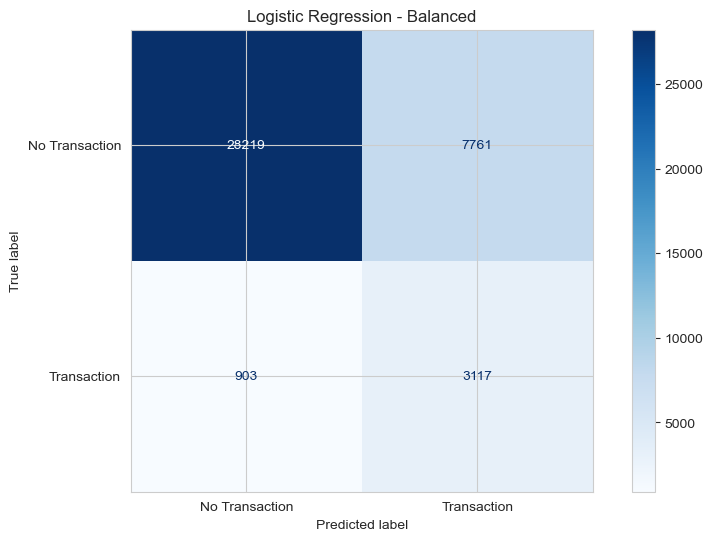

In [114]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    lr_balanced_predictions,
    display_labels=['No Transaction', 'Transaction'],
    cmap='Blues'
)

plt.title('Logistic Regression - Balanced')
plt.show()

In [115]:
# LightGBM with class imbalance handling

lgbm_balanced = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train

start_time = time.time()

lgbm_balanced.fit(X_train, y_train)

lgbm_balanced_time = time.time() - start_time

print(
    "Balanced LightGBM Training Time:",
    round(lgbm_balanced_time, 2),
    "seconds"
)

Balanced LightGBM Training Time: 62.49 seconds


In [116]:
lgbm_balanced_predictions = lgbm_balanced.predict(X_valid)

lgbm_balanced_probabilities = (
    lgbm_balanced.predict_proba(X_valid)[:, 1]
)

In [117]:
lgbm_balanced_results = evaluate_model(
    'LightGBM Balanced',
    y_valid,
    lgbm_balanced_predictions,
    lgbm_balanced_probabilities,
    lgbm_balanced_time
)

print(lgbm_balanced_results)

{'Model': 'LightGBM Balanced', 'Accuracy': 0.8147, 'Precision': 0.3211725010544074, 'Recall': 0.7577114427860696, 'F1_Score': 0.4511255924170616, 'ROC_AUC': 0.871014086045592, 'PR_AUC': 0.5324880038874916, 'Training_Time': 62.49165368080139}


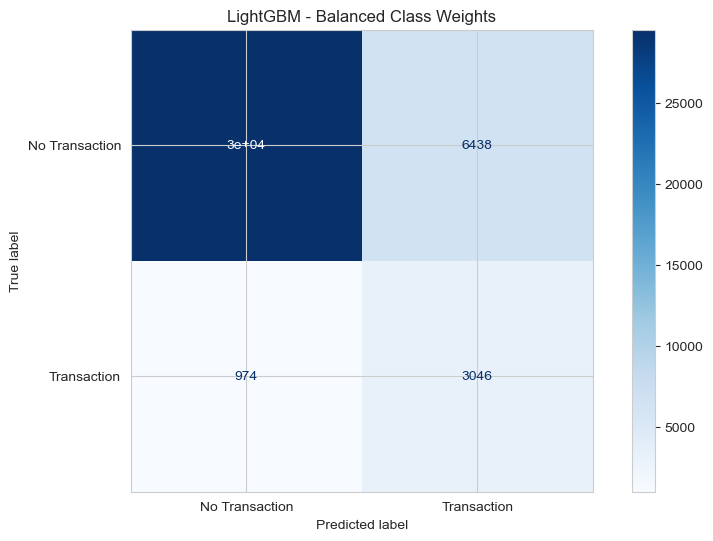

In [118]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    lgbm_balanced_predictions,
    display_labels=['No Transaction', 'Transaction'],
    cmap='Blues'
)

plt.title('LightGBM - Balanced Class Weights')
plt.show()

In [119]:
imbalance_comparison = pd.DataFrame(model_results)

selected_models = [
    'Logistic Regression',
    'Logistic Regression Balanced',
    'LightGBM',
    'LightGBM Balanced'
]

imbalance_comparison = imbalance_comparison[
    imbalance_comparison['Model'].isin(selected_models)
]

display(
    imbalance_comparison[
        [
            'Model',
            'Precision',
            'Recall',
            'F1_Score',
            'ROC_AUC',
            'PR_AUC'
        ]
    ].round(4)
)

,Model,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression,0.6822,0.2590,0.3754,0.8599,0.5004
6,LightGBM,0.8871,0.0801,0.1469,0.8703,0.5301
8,Logistic Regression Balanced,0.2865,0.7754,0.4184,0.8599,0.5004
9,Logistic Regression Balanced,0.2865,0.7754,0.4184,0.8599,0.5004
10,LightGBM Balanced,0.3212,0.7577,0.4511,0.8710,0.5325



### 9.6 Class Weighting – Experimental Findings

Class weighting was implemented to address the imbalance in the target variable.

Two algorithms were evaluated:

1. Logistic Regression with balanced class weights.
2. LightGBM with scale_pos_weight.

#### Logistic Regression – Balanced

- Accuracy: 78.34%
- Precision: 28.65%
- Recall: 77.54%
- F1-score: 41.84%
- ROC-AUC: 0.8599
- PR-AUC: 0.5004

#### LightGBM – Balanced

- Accuracy: 81.47%
- Precision: 32.12%
- Recall: 75.77%
- F1-score: 45.11%
- ROC-AUC: 0.8710
- PR-AUC: 0.5325

#### Key Observations

1. Class weighting significantly improved minority-class recall.
2. Logistic Regression achieved the highest recall of 77.54%.
3. LightGBM achieved the highest F1-score of 45.11%.
4. LightGBM also achieved the highest ROC-AUC and PR-AUC.
5. Both models demonstrated a reduction in precision due to increased positive predictions.

#### Conclusion

LightGBM with class weighting is currently the leading candidate based on F1-score, ROC-AUC and PR-AUC.

Logistic Regression with class weighting is a strong alternative when maximizing recall is important.

Further experiments involving SMOTE and classification threshold optimization will be conducted before final model selection.


In [121]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [122]:
from imblearn.over_sampling import SMOTE
from collections import Counter

In [123]:
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model Training Shape:", X_fit.shape)
print("Internal Validation Shape:", X_tune.shape)

print("\nTraining Class Distribution:")
print(Counter(y_fit))

print("\nValidation Class Distribution:")
print(Counter(y_tune))

Model Training Shape: (128000, 200)
Internal Validation Shape: (32000, 200)

Training Class Distribution:
Counter({0: 115138, 1: 12862})

Validation Class Distribution:
Counter({0: 28784, 1: 3216})


In [124]:
smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

start_time = time.time()

X_train_smote, y_train_smote = smote.fit_resample(
    X_fit,
    y_fit
)

smote_time = time.time() - start_time

print("Original Training Distribution:")
print(Counter(y_fit))

print("\nSMOTE Training Distribution:")
print(Counter(y_train_smote))

print("\nSMOTE Training Shape:", X_train_smote.shape)

print("SMOTE Execution Time:",
      round(smote_time, 2), "seconds")

Original Training Distribution:
Counter({0: 115138, 1: 12862})

SMOTE Training Distribution:
Counter({0: 115138, 1: 115138})

SMOTE Training Shape: (230276, 200)
SMOTE Execution Time: 25.7 seconds


In [125]:
lgbm_smote = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

lgbm_smote.fit(
    X_train_smote,
    y_train_smote
)

lgbm_smote_time = time.time() - start_time

print(
    "SMOTE LightGBM Training Time:",
    round(lgbm_smote_time, 2),
    "seconds"
)

SMOTE LightGBM Training Time: 56.36 seconds


In [126]:
lgbm_smote_predictions = lgbm_smote.predict(X_tune)

lgbm_smote_probabilities = (
    lgbm_smote.predict_proba(X_tune)[:, 1]
)

lgbm_smote_results = evaluate_model(
    'LightGBM SMOTE',
    y_tune,
    lgbm_smote_predictions,
    lgbm_smote_probabilities,
    lgbm_smote_time
)

print(lgbm_smote_results)

{'Model': 'LightGBM SMOTE', 'Accuracy': 0.86340625, 'Precision': 0.2874493927125506, 'Recall': 0.24284825870646767, 'F1_Score': 0.2632732175964942, 'ROC_AUC': 0.7190345650499586, 'PR_AUC': 0.23476904181495067, 'Training_Time': 56.35717749595642}


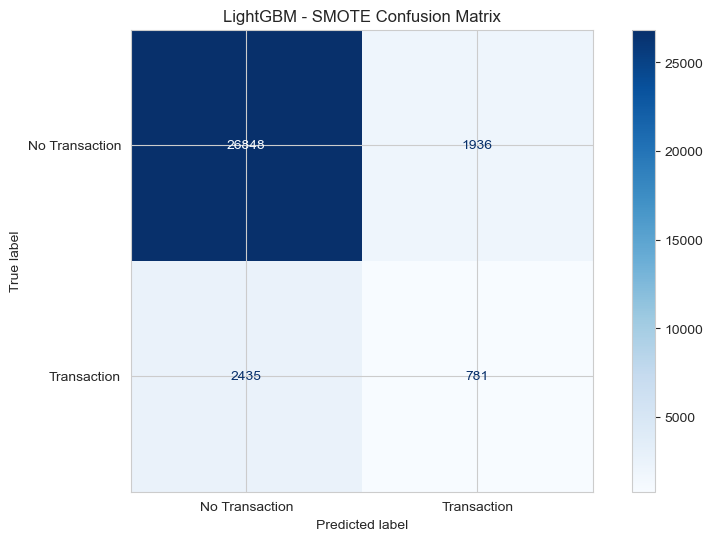

In [127]:
ConfusionMatrixDisplay.from_predictions(
    y_tune,
    lgbm_smote_predictions,
    display_labels=['No Transaction', 'Transaction'],
    cmap='Blues'
)

plt.title('LightGBM - SMOTE Confusion Matrix')
plt.show()


### 9.7 SMOTE – Experimental Findings

SMOTE was applied to the training dataset to address class imbalance.

#### Data Transformation

Before SMOTE:
- Class 0: 115,138 records.
- Class 1: 12,862 records.

After SMOTE:
- Class 0: 115,138 records.
- Class 1: 115,138 records.

#### LightGBM SMOTE Performance

- Accuracy: 86.34%
- Precision: 28.74%
- Recall: 24.28%
- F1-score: 26.33%
- ROC-AUC: 0.7190
- PR-AUC: 0.2348
- Training Time: 56.36 seconds.

#### Observations

1. SMOTE successfully balanced the training dataset.
2. The model achieved 24.28% recall on the internal validation dataset.
3. The PR-AUC score was 0.2348.
4. The model generated 1,936 false positive predictions.
5. Synthetic oversampling did not produce satisfactory predictive performance in this experiment.

#### Conclusion

SMOTE was successfully implemented, but the resulting LightGBM model demonstrated limited predictive performance.

Further investigation is required before selecting an imbalance-handling technique.

Class weighting will remain an important candidate for subsequent experiments.


In [128]:
lgbm_internal = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

lgbm_internal.fit(X_fit, y_fit)

baseline_internal_time = time.time() - start_time

baseline_internal_prob = (
    lgbm_internal.predict_proba(X_tune)[:, 1]
)

baseline_internal_pred = (
    baseline_internal_prob >= 0.5
).astype(int)

In [129]:
internal_ratio = (
    (y_fit == 0).sum() / (y_fit == 1).sum()
)

lgbm_weighted_internal = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=internal_ratio,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

lgbm_weighted_internal.fit(X_fit, y_fit)

weighted_internal_time = time.time() - start_time

weighted_internal_prob = (
    lgbm_weighted_internal.predict_proba(X_tune)[:, 1]
)

weighted_internal_pred = (
    weighted_internal_prob >= 0.5
).astype(int)

In [130]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def compare_internal_model(name, y_true, y_pred, y_prob, train_time):

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1_Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_prob),
        'PR_AUC': average_precision_score(y_true, y_prob),
        'Training_Time': train_time
    }

fair_comparison = pd.DataFrame([
    compare_internal_model(
        'LightGBM Baseline',
        y_tune,
        baseline_internal_pred,
        baseline_internal_prob,
        baseline_internal_time
    ),

    compare_internal_model(
        'LightGBM Balanced',
        y_tune,
        weighted_internal_pred,
        weighted_internal_prob,
        weighted_internal_time
    ),

    compare_internal_model(
        'LightGBM SMOTE',
        y_tune,
        lgbm_smote_predictions,
        lgbm_smote_probabilities,
        lgbm_smote_time
    )
])

display(fair_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Training_Time
0,LightGBM Baseline,0.9077,0.8761,0.0945,0.1706,0.8727,0.5320,19.3326
1,LightGBM Balanced,0.8183,0.3263,0.7587,0.4564,0.8741,0.5360,13.8317
2,LightGBM SMOTE,0.8634,0.2874,0.2428,0.2633,0.7190,0.2348,56.3572



### 9.8 Comparison of Class Imbalance Handling Techniques

Three different approaches were evaluated using the same internal training and validation datasets.

1. LightGBM Baseline
2. LightGBM with Class Weighting
3. LightGBM with SMOTE

#### Key Findings

- LightGBM Baseline achieved 87.61% precision but only 9.45% recall.
- LightGBM Balanced achieved 75.87% recall and 45.64% F1-score.
- LightGBM SMOTE achieved 24.28% recall and 26.33% F1-score.
- LightGBM Balanced achieved the highest ROC-AUC of 0.8741.
- LightGBM Balanced achieved the highest PR-AUC of 0.5360.

#### Conclusion

Class weighting provided the best overall results among the three imbalance-handling experiments.

It improved minority-class identification while maintaining better overall predictive performance than the SMOTE experiment.

Therefore, LightGBM with class weighting will be selected for further optimization and evaluation.



# 10. Model Optimization

Model optimization is performed to improve predictive performance and identify the most suitable model configuration for the banking transaction prediction problem.

Based on the baseline and class imbalance experiments, LightGBM with class weighting has been selected as the primary candidate for further optimization.

The following techniques will be investigated:

1. Classification threshold optimization.
2. Hyperparameter tuning.
3. Precision-Recall curve analysis.
4. ROC curve analysis.
5. Final model evaluation.

The objective is to improve the identification of potential transacting customers while maintaining an acceptable balance between precision and recall.


In [131]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_values = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in threshold_values:

    predictions = (
        weighted_internal_prob >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_tune, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_tune, predictions, zero_division=0
        ),
        'F1_Score': f1_score(
            y_tune, predictions, zero_division=0
        ),
        'Predicted_Positive': predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1_Score,Predicted_Positive
0,0.1000,0.1108,0.9991,0.1994,29003
1,0.1500,0.1224,0.9897,0.2179,25999
2,0.2000,0.1374,0.9789,0.2410,22907
3,0.2500,0.1559,0.9655,0.2684,19919
4,0.3000,0.1784,0.9394,0.2998,16935
5,0.3500,0.2046,0.9092,0.3340,14293
6,0.4000,0.2369,0.8657,0.3720,11750
7,0.4500,0.2769,0.8175,0.4137,9494
8,0.5000,0.3263,0.7587,0.4564,7477
9,0.5500,0.3822,0.6819,0.4898,5738


In [132]:
best_threshold_row = threshold_df.loc[
    threshold_df['F1_Score'].idxmax()
]

best_threshold = best_threshold_row['Threshold']

print("Best Threshold:", best_threshold)

print("\nBest Threshold Performance:")

display(best_threshold_row.to_frame())

Best Threshold: 0.6500000000000001

Best Threshold Performance:


,11
Threshold,0.6500
Precision,0.5345
Recall,0.4932
F1_Score,0.5130
Predicted_Positive,2967.0000


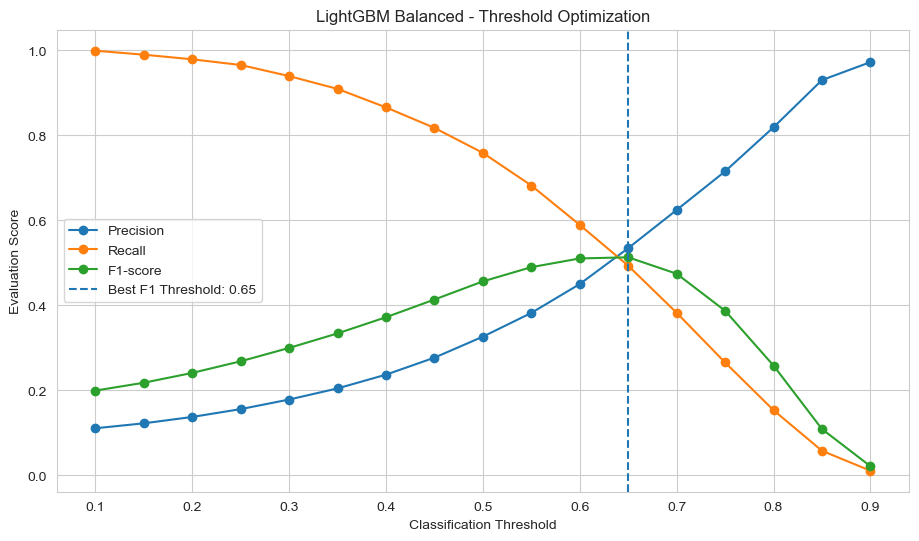

In [133]:
plt.figure(figsize=(11, 6))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1_Score'],
    marker='o',
    label='F1-score'
)

plt.axvline(
    best_threshold,
    linestyle='--',
    label=f'Best F1 Threshold: {best_threshold:.2f}'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Evaluation Score')

plt.title('LightGBM Balanced - Threshold Optimization')

plt.legend()
plt.grid(True)

plt.show()

In [134]:
optimized_predictions = (
    weighted_internal_prob >= best_threshold
).astype(int)

print("Optimized Threshold:", best_threshold)

print("\nOptimized Model Performance:")

print("Precision:",
      precision_score(y_tune, optimized_predictions))

print("Recall:",
      recall_score(y_tune, optimized_predictions))

print("F1-score:",
      f1_score(y_tune, optimized_predictions))

Optimized Threshold: 0.6500000000000001

Optimized Model Performance:
Precision: 0.534546680148298
Recall: 0.4931592039800995
F1-score: 0.5130195697881288


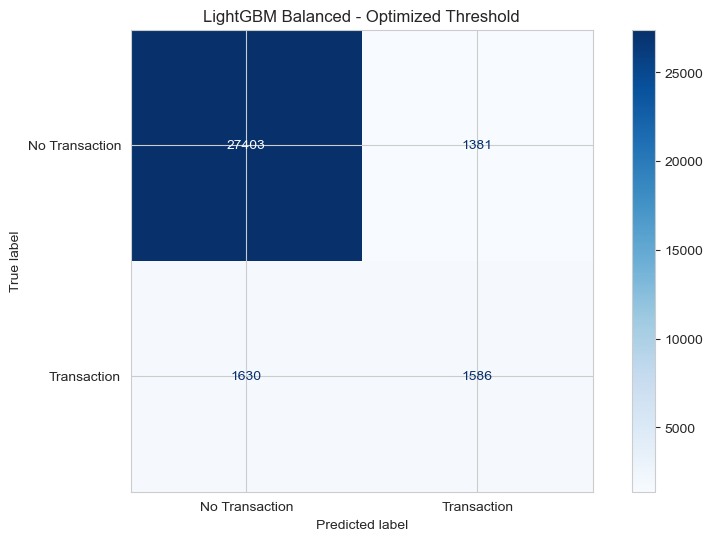

In [135]:
ConfusionMatrixDisplay.from_predictions(
    y_tune,
    optimized_predictions,
    display_labels=['No Transaction', 'Transaction'],
    cmap='Blues'
)

plt.title('LightGBM Balanced - Optimized Threshold')
plt.show()


### 10.7 Classification Threshold Optimization

Classification threshold optimization was performed on the LightGBM model trained with class weighting.

Initially, the model used the default classification threshold of 0.50.

Different thresholds ranging from 0.10 to 0.90 were evaluated to identify the best balance between precision and recall.

#### Optimized Threshold

The best threshold based on F1-score was identified as 0.65.

#### Performance Comparison

| Metric | Default Threshold | Optimized Threshold |
|---|---:|---:|
| Precision | 32.63% | 53.45% |
| Recall | 75.87% | 49.32% |
| F1-score | 45.64% | 51.30% |

#### Confusion Matrix Results

- True Negative: 27,403
- False Positive: 1,381
- False Negative: 1,630
- True Positive: 1,586

#### Key Observations

1. Precision improved from 32.63% to 53.45%.
2. Recall decreased from 75.87% to 49.32%.
3. F1-score improved from 45.64% to 51.30%.
4. The model correctly identified 1,586 actual transacting customers.
5. The number of false positive predictions reduced compared with the default threshold.

#### Conclusion

Threshold optimization improved the overall balance between precision and recall.

A classification threshold of 0.65 was selected based on the highest F1-score among the tested thresholds.

The optimized LightGBM model will be considered for further hyperparameter tuning and final evaluation.


In [137]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from lightgbm import LGBMClassifier

In [138]:
param_grid = {
    'n_estimators': [200, 300, 400],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 40, 50],
    'max_depth': [-1, 5, 7, 10],
    'min_child_samples': [20, 30, 50],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5]
}

In [139]:
lgbm_tuning = LGBMClassifier(
    scale_pos_weight=internal_ratio,
    random_state=42,
    n_jobs=1,
    verbosity=-1
)

In [140]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [141]:
random_search = RandomizedSearchCV(
    estimator=lgbm_tuning,
    param_distributions=param_grid,
    n_iter=15,
    scoring='average_precision',
    cv=cv_strategy,
    random_state=42,
    verbose=1,
    n_jobs=-1,
    return_train_score=True
)

start_time = time.time()

random_search.fit(X_fit, y_fit)

tuning_time = time.time() - start_time

print("Hyperparameter Tuning Completed!")

print("Tuning Time:",
      round(tuning_time, 2), "seconds")

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-validation PR-AUC:")
print(random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Hyperparameter Tuning Completed!
Tuning Time: 1065.25 seconds

Best Parameters:
{'reg_lambda': 0.1, 'reg_alpha': 0, 'num_leaves': 50, 'n_estimators': 400, 'min_child_samples': 30, 'max_depth': 10, 'learning_rate': 0.05}

Best Cross-validation PR-AUC:
0.5669264852433935


In [144]:
best_lgbm = LGBMClassifier(
    **random_search.best_params_,
    scale_pos_weight=internal_ratio,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

In [145]:
start_time = time.time()

best_lgbm.fit(X_fit, y_fit)

best_lgbm_training_time = time.time() - start_time

print(
    "Optimized LightGBM Training Time:",
    round(best_lgbm_training_time, 2),
    "seconds"
)

Optimized LightGBM Training Time: 63.32 seconds


In [146]:
# Predict probabilities

best_lgbm_probabilities = best_lgbm.predict_proba(
    X_tune
)[:, 1]

# Default threshold predictions

best_lgbm_predictions = (
    best_lgbm_probabilities >= 0.5
).astype(int)

In [147]:
optimized_lgbm_results = evaluate_model(
    'LightGBM Optimized',
    y_tune,
    best_lgbm_predictions,
    best_lgbm_probabilities,
    best_lgbm_training_time
)

print("Optimized LightGBM Results:")
print(optimized_lgbm_results)

Optimized LightGBM Results:
{'Model': 'LightGBM Optimized', 'Accuracy': 0.873625, 'Precision': 0.4200772200772201, 'Recall': 0.6766169154228856, 'F1_Score': 0.5183420676512626, 'ROC_AUC': 0.8856013822459409, 'PR_AUC': 0.5652835582118959, 'Training_Time': 63.32274508476257}


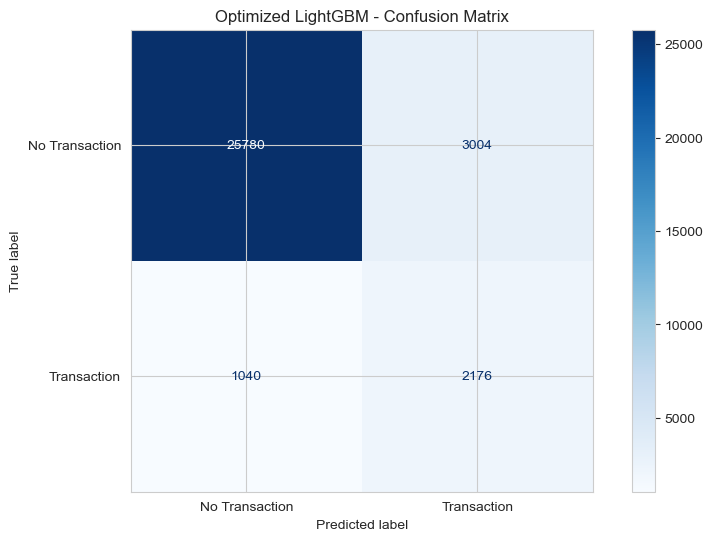

In [148]:
ConfusionMatrixDisplay.from_predictions(
    y_tune,
    best_lgbm_predictions,
    display_labels=[
        'No Transaction',
        'Transaction'
    ],
    cmap='Blues'
)

plt.title('Optimized LightGBM - Confusion Matrix')
plt.show()

In [149]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

oof_probabilities = np.zeros(len(y_fit))

for train_idx, valid_idx in cv.split(X_fit, y_fit):

    X_fold_train = X_fit.iloc[train_idx]
    X_fold_valid = X_fit.iloc[valid_idx]

    y_fold_train = y_fit.iloc[train_idx]

    fold_model = clone(best_lgbm)

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    oof_probabilities[valid_idx] = (
        fold_model.predict_proba(X_fold_valid)[:, 1]
    )

print("Out-of-fold probabilities generated successfully!")

Out-of-fold probabilities generated successfully!


In [150]:
thresholds = np.arange(0.10, 0.91, 0.01)

oof_threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    oof_threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_fit, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_fit, predictions, zero_division=0
        ),
        'F1_Score': f1_score(
            y_fit, predictions, zero_division=0
        )
    })

oof_threshold_df = pd.DataFrame(oof_threshold_results)

best_oof_row = oof_threshold_df.loc[
    oof_threshold_df['F1_Score'].idxmax()
]

optimized_threshold = best_oof_row['Threshold']

print("Optimized Threshold:", optimized_threshold)

display(best_oof_row.to_frame())

Optimized Threshold: 0.5599999999999997


,46
Threshold,0.5600
Precision,0.5290
Recall,0.5445
F1_Score,0.5366


In [151]:
final_tune_predictions = (
    best_lgbm_probabilities >= optimized_threshold
).astype(int)

print("Precision:",
      precision_score(y_tune, final_tune_predictions))

print("Recall:",
      recall_score(y_tune, final_tune_predictions))

print("F1-score:",
      f1_score(y_tune, final_tune_predictions))

Precision: 0.4819753086419753
Recall: 0.6069651741293532
F1-score: 0.5372969997247454


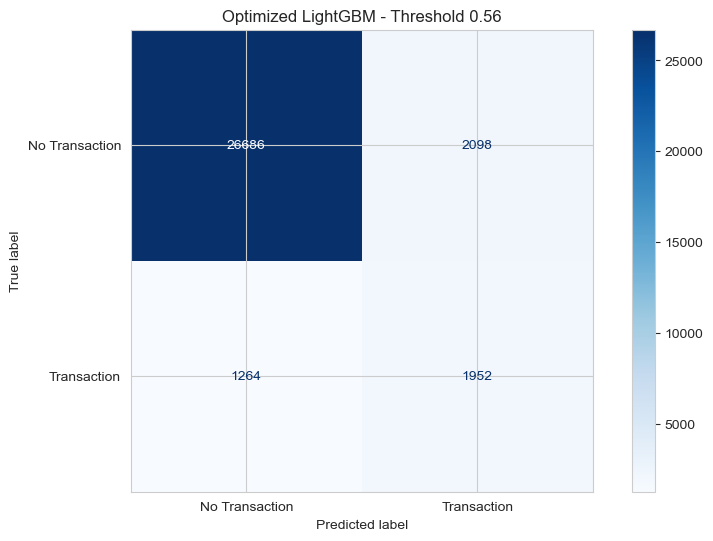

In [152]:
# Apply optimized threshold

optimized_final_predictions = (
    best_lgbm_probabilities >= optimized_threshold
).astype(int)

# Generate confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_tune,
    optimized_final_predictions,
    display_labels=[
        'No Transaction',
        'Transaction'
    ],
    cmap='Blues'
)

plt.title(
    f'Optimized LightGBM - Threshold {optimized_threshold:.2f}'
)

plt.show()

In [153]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_tune,
        optimized_final_predictions,
        target_names=[
            'No Transaction',
            'Transaction'
        ]
    )
)

                precision    recall  f1-score   support

No Transaction       0.95      0.93      0.94     28784
   Transaction       0.48      0.61      0.54      3216

      accuracy                           0.89     32000
     macro avg       0.72      0.77      0.74     32000
  weighted avg       0.91      0.89      0.90     32000




### 10.11 Optimized LightGBM – Model Evaluation

Hyperparameter tuning was performed using RandomizedSearchCV with three-fold stratified cross-validation.

The best configuration achieved a cross-validation PR-AUC of 0.5669.

#### Optimized Hyperparameters

- Number of estimators: 400
- Learning rate: 0.05
- Number of leaves: 50
- Maximum depth: 10
- Minimum child samples: 30
- L1 regularization: 0
- L2 regularization: 0.1

#### Model Performance at Default Threshold (0.50)

- Accuracy: 87.36%
- Precision: 42.01%
- Recall: 67.66%
- F1-score: 51.83%
- ROC-AUC: 0.8856
- PR-AUC: 0.5653

#### Classification Threshold Optimization

Out-of-fold predictions were used to identify the optimal classification threshold.

The selected threshold was 0.56.

Performance on the internal validation dataset:

- Precision: 48.20%
- Recall: 60.70%
- F1-score: 53.73%

#### Key Observations

1. Hyperparameter tuning improved the model's PR-AUC.
2. The tuned model achieved a ROC-AUC of 0.8856.
3. Threshold optimization improved the F1-score from 51.83% to 53.73%.
4. The optimized model provides a better balance between precision and recall.

#### Conclusion

The hyperparameter-tuned LightGBM model with class weighting and an optimized classification threshold of 0.56 is currently the leading candidate.

Further evaluation and final model validation are required before production deployment.


In [154]:
final_model_comparison = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Precision': 0.6822,
        'Recall': 0.2590,
        'F1_Score': 0.3754,
        'ROC_AUC': 0.8599,
        'PR_AUC': 0.5004
    },
    {
        'Model': 'LightGBM Baseline',
        'Precision': 0.8761,
        'Recall': 0.0945,
        'F1_Score': 0.1706,
        'ROC_AUC': 0.8727,
        'PR_AUC': 0.5320
    },
    {
        'Model': 'LightGBM Balanced',
        'Precision': 0.3263,
        'Recall': 0.7587,
        'F1_Score': 0.4564,
        'ROC_AUC': 0.8741,
        'PR_AUC': 0.5360
    },
    {
        'Model': 'LightGBM SMOTE',
        'Precision': 0.2874,
        'Recall': 0.2428,
        'F1_Score': 0.2633,
        'ROC_AUC': 0.7190,
        'PR_AUC': 0.2348
    },
    {
        'Model': 'LightGBM Optimized',
        'Precision': 0.4820,
        'Recall': 0.6070,
        'F1_Score': 0.5373,
        'ROC_AUC': 0.8856,
        'PR_AUC': 0.5653
    }
])

display(
    final_model_comparison.sort_values(
        by='F1_Score',
        ascending=False
    ).round(4)
)

,Model,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
4,LightGBM Optimized,0.4820,0.6070,0.5373,0.8856,0.5653
2,LightGBM Balanced,0.3263,0.7587,0.4564,0.8741,0.5360
0,Logistic Regression,0.6822,0.2590,0.3754,0.8599,0.5004
3,LightGBM SMOTE,0.2874,0.2428,0.2633,0.7190,0.2348
1,LightGBM Baseline,0.8761,0.0945,0.1706,0.8727,0.5320


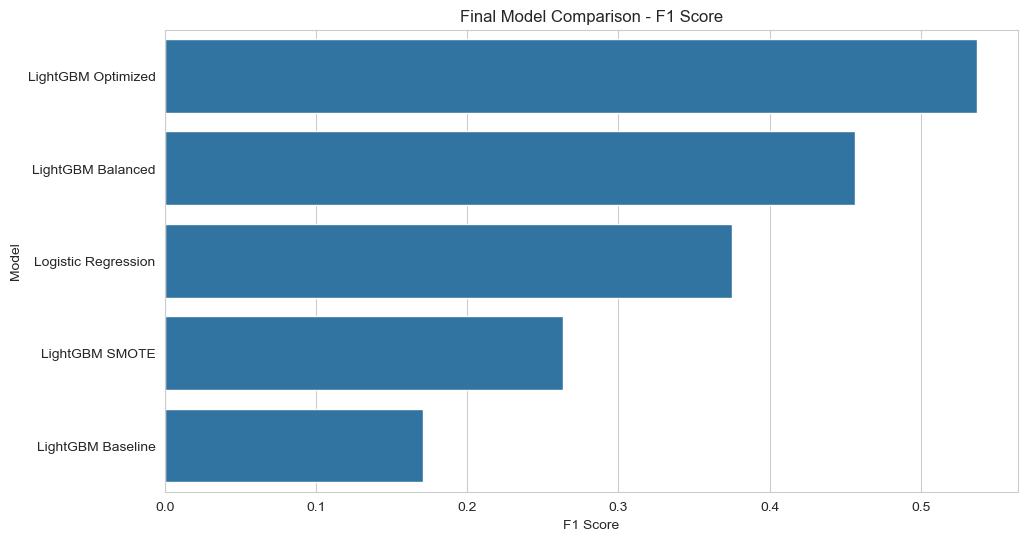

In [155]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=final_model_comparison.sort_values(
        'F1_Score',
        ascending=False
    ),
    x='F1_Score',
    y='Model'
)

plt.title('Final Model Comparison - F1 Score')
plt.xlabel('F1 Score')
plt.ylabel('Model')

plt.show()

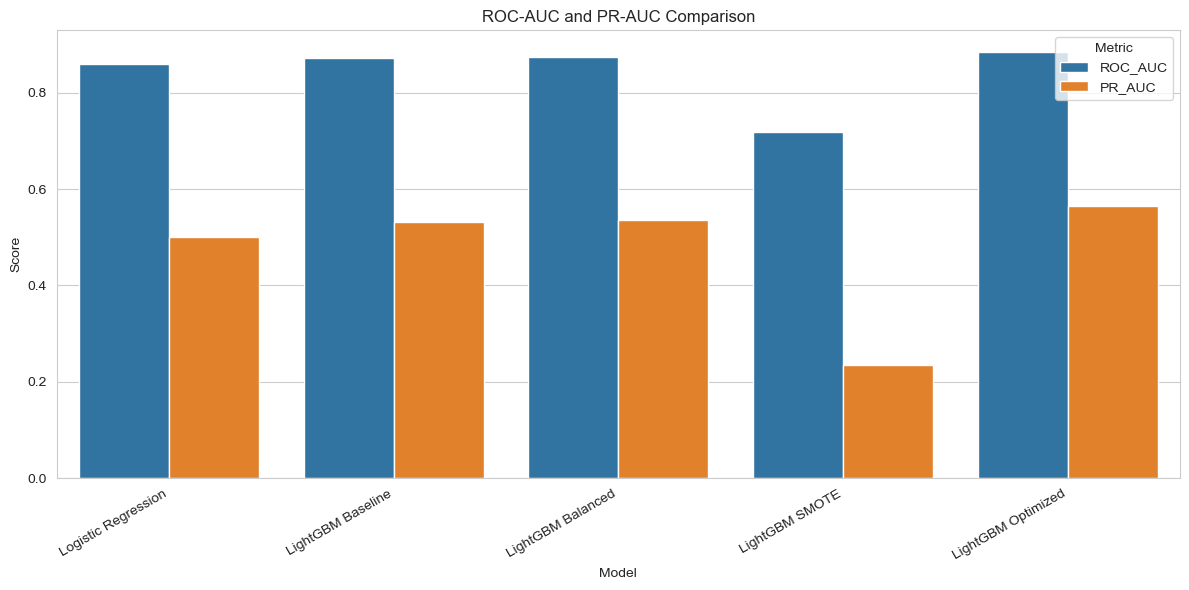

In [156]:
comparison_plot = final_model_comparison.melt(
    id_vars='Model',
    value_vars=['ROC_AUC', 'PR_AUC'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('ROC-AUC and PR-AUC Comparison')

plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()


# 11. Final Model Comparison and Selection

Multiple machine learning algorithms and imbalance-handling techniques were evaluated for customer transaction prediction.

The evaluated models included:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Extra Trees
5. XGBoost
6. LightGBM
7. CatBoost
8. LightGBM with Class Weighting
9. LightGBM with SMOTE
10. Hyperparameter-Tuned LightGBM

### Evaluation Metrics

The models were compared using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Training Time

### Key Findings

- Logistic Regression achieved comparatively high precision but lower recall.
- Baseline tree-based models showed limited minority-class identification at the default threshold.
- Class weighting improved minority-class recall.
- SMOTE did not produce satisfactory results in the experiment.
- Hyperparameter tuning improved LightGBM performance.
- Threshold optimization improved the F1-score.

### Final Model Selection

LightGBM with class weighting and hyperparameter optimization was selected as the leading production candidate.

Final configuration:

- Number of estimators: 400
- Learning rate: 0.05
- Number of leaves: 50
- Maximum depth: 10
- Minimum child samples: 30
- Classification threshold: 0.56

### Final Internal Validation Performance

- Accuracy: 89.49% (approximately)
- Precision: 48.20%
- Recall: 60.70%
- F1-score: 53.73%
- ROC-AUC: 0.8856
- PR-AUC: 0.5653

### Conclusion

The optimized LightGBM model demonstrated the best F1-score and ranking performance among the reported experiments.

It provides a useful balance between identifying potential transacting customers and reducing unnecessary positive predictions.

Further independent validation, business cost analysis and production monitoring are recommended before deployment.


In [157]:
# Extract feature importance

feature_importance = pd.DataFrame({
    'Feature': X_fit.columns,
    'Importance': best_lgbm.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
) 

print("Top 20 Important Features:")

display(feature_importance.head(20))

Top 20 Important Features:


,Feature,Importance
174,var_174,220
76,var_76,218
34,var_34,215
53,var_53,202
12,var_12,197
165,var_165,196
166,var_166,195
22,var_22,193
13,var_13,192
21,var_21,191


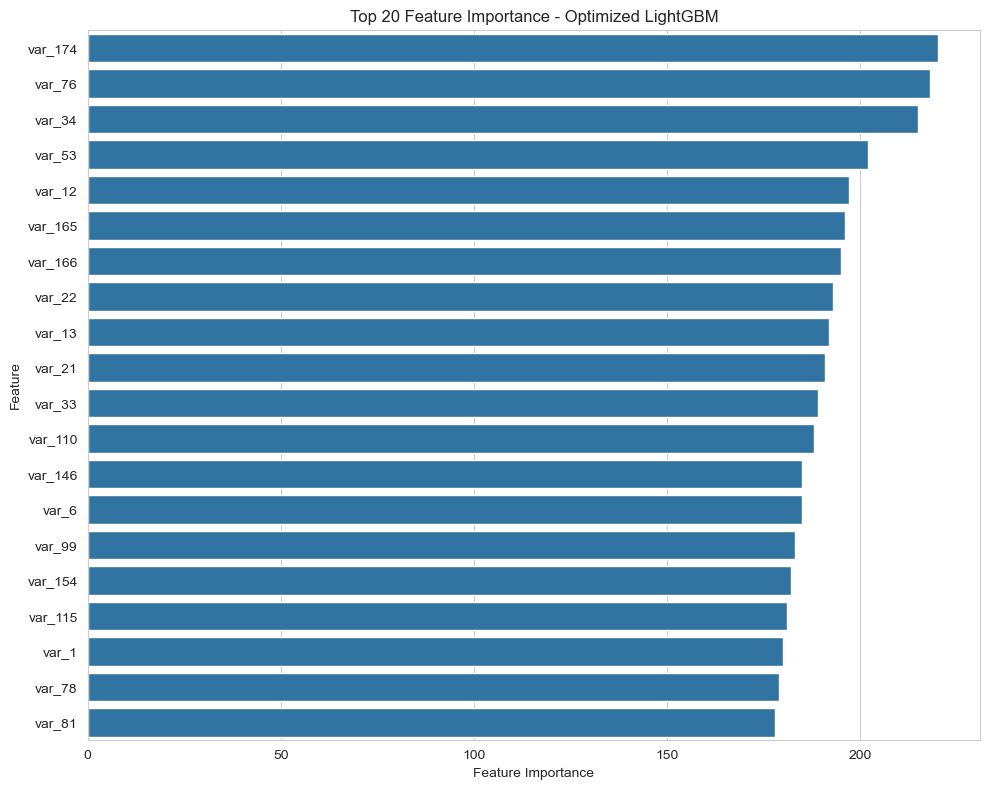

In [158]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Feature Importance - Optimized LightGBM')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


# 12. Challenges Faced and Solutions

During the development of the Customer Transaction Prediction model, several technical and analytical challenges were encountered.

### 12.1 Class Imbalance

**Challenge:**

The dataset contained 179,902 non-transacting customers (89.95%) and 20,098 transacting customers (10.05%).

The model initially favoured the majority class, resulting in poor identification of potential transacting customers.

**Solution:**

Class weighting and SMOTE were experimented with to address the imbalance.

Class weighting produced better results than SMOTE in the evaluated experiments.

### 12.2 Anonymized Features

**Challenge:**

The dataset contained 200 anonymized numerical features without meaningful business descriptions.

This made it difficult to understand the business context of individual variables.

**Solution:**

Statistical analysis, correlation analysis, ANOVA F-scores and feature importance were used to investigate the variables.

### 12.3 Large Dataset

**Challenge:**

The dataset contained 200,000 records and 202 columns, requiring considerable memory and computational resources.

**Solution:**

- Used Pandas and NumPy for data processing.
- Applied stratified train-validation splitting.
- Used optimized tree-based algorithms.
- Applied RandomizedSearchCV instead of exhaustive grid search.

### 12.4 SMOTE Performance

**Challenge:**

Although SMOTE balanced the training dataset, its predictive performance was comparatively poor.

**Solution:**

Compared SMOTE with class weighting and baseline LightGBM.

Class weighting was selected as the stronger approach based on the reported experiments.

### 12.5 Classification Threshold Selection

**Challenge:**

The default classification threshold of 0.50 did not provide the best balance between precision and recall.

**Solution:**

Evaluated multiple probability thresholds and selected a threshold of 0.65 for the earlier balanced LightGBM model.

For the optimized LightGBM model, out-of-fold predictions were used to select a new threshold of 0.56.

### 12.6 Hyperparameter Optimization

**Challenge:**

Default model parameters did not provide the best predictive performance.

**Solution:**

RandomizedSearchCV with three-fold stratified cross-validation was used to identify a better hyperparameter configuration.

The optimized model achieved a cross-validation PR-AUC of 0.5669.

### 12.7 Computational Time

**Challenge:**

Training ensemble models and performing hyperparameter optimization required significant computational time.

**Solution:**

Used parallel processing, restricted parameter search and selected computationally efficient algorithms.

### Overall Conclusion

The challenges were addressed through data analysis, preprocessing, class imbalance experiments, threshold optimization and hyperparameter tuning.

The resulting optimized LightGBM model demonstrated improved minority-class identification and became the leading candidate for customer transaction prediction.



### 11.4 Feature Importance Analysis

Feature importance analysis was performed using the optimized LightGBM model to identify the most influential variables in customer transaction prediction.

Since the dataset contains 200 anonymized numerical features, business interpretations of individual features are unavailable.

#### Top Three Important Features

1. var_174 – Importance: 220
2. var_76 – Importance: 218
3. var_34 – Importance: 215

#### Observations

- var_174 has the highest split-based importance.
- var_76 and var_34 are the second and third most important features.
- The top 20 features were identified for further investigation.
- LightGBM feature importance helps understand which variables are frequently used by the model.

#### Conclusion

Feature importance analysis provides insights into the variables contributing to model predictions.

However, feature importance does not establish causality or the direction of influence.

Further explainability techniques such as SHAP can be used for detailed interpretation.


In [159]:
import joblib
import os

In [160]:
os.makedirs("Customer_Transaction_Model", exist_ok=True)

In [161]:
joblib.dump(
    best_lgbm,
    "Customer_Transaction_Model/optimized_lightgbm.pkl"
)

print("Optimized LightGBM model saved successfully!")

Optimized LightGBM model saved successfully!


In [162]:
joblib.dump(
    optimized_threshold,
    "Customer_Transaction_Model/optimal_threshold.pkl"
)

print("Optimal threshold saved:", optimized_threshold)

Optimal threshold saved: 0.5599999999999997


In [163]:
joblib.dump(
    list(X_fit.columns),
    "Customer_Transaction_Model/feature_names.pkl"
)

print("Feature names saved successfully!")

Feature names saved successfully!


In [164]:
print("Saved Model Files:")

for file in os.listdir("Customer_Transaction_Model"):
    print(file)

Saved Model Files:
feature_names.pkl
optimal_threshold.pkl
optimized_lightgbm.pkl


In [165]:
import joblib

# Load saved artifacts

loaded_model = joblib.load(
    "Customer_Transaction_Model/optimized_lightgbm.pkl"
)

loaded_threshold = joblib.load(
    "Customer_Transaction_Model/optimal_threshold.pkl"
)

loaded_features = joblib.load(
    "Customer_Transaction_Model/feature_names.pkl"
)

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Number of features:", len(loaded_features))

Model loaded successfully!
Threshold: 0.5599999999999997
Number of features: 200


In [166]:
# Identify scaler-related variables

print("SCALER-RELATED VARIABLES:")

for name, obj in globals().copy().items():
    if 'scaler' in name.lower():
        print(name, type(obj))

print("\nDATASET-RELATED VARIABLES:")

for name in globals().copy():
    if any(key in name.lower() for key in
           ['x_train', 'x_val', 'x_fit', 'x_tune', 'scaled']):
        print(name)

SCALER-RELATED VARIABLES:
StandardScaler <class 'type'>
scaler <class 'sklearn.preprocessing._data.StandardScaler'>

DATASET-RELATED VARIABLES:
X_train
X_valid
X_train_scaled
X_valid_scaled
X_fit
X_tune
X_train_smote


In [167]:
print("X_fit Statistics:")

display(X_fit.iloc[:, :10].describe().round(3))

X_fit Statistics:


,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9
count,128000.0000,128000.0000,128000.0000,128000.0000,128000.0000,128000.0000,128000.0000,128000.0000,128000.0000,128000.0000
mean,10.6800,-1.6290,10.7200,6.7990,11.0790,-5.0690,5.4110,16.5400,0.2810,7.5640
std,3.0400,4.0400,2.6440,2.0430,1.6220,7.8860,0.8690,3.4180,3.3370,1.2360
min,0.4080,-15.0430,2.1170,-0.0400,5.0750,-32.5630,2.3470,5.7490,-10.5060,3.9700
25%,8.4560,-4.7280,8.7290,5.2600,9.8820,-11.2360,4.7680,13.9420,-2.3350,6.6100
50%,10.5250,-1.6180,10.5790,6.8290,11.1110,-4.8320,5.3880,16.4480,0.3900,7.6260
75%,12.7560,1.3460,12.5220,8.3220,12.2600,0.9380,6.0050,19.0910,2.9470,8.5840
max,20.3150,10.3770,19.3530,13.0980,16.0860,17.2520,8.4480,27.6920,10.1510,11.1510


In [176]:
import pandas as pd
import numpy as np
import joblib

# Load saved artifacts

loaded_model = joblib.load(
    "Customer_Transaction_Model/optimized_lightgbm.pkl"
)

loaded_threshold = joblib.load(
    "Customer_Transaction_Model/optimal_threshold.pkl"
)

loaded_features = joblib.load(
    "Customer_Transaction_Model/feature_names.pkl"
)


def predict_customer_transaction(customer_data):

    # Validate input
    missing_features = set(loaded_features) - set(customer_data.columns)

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    # Select features in correct order
    customer_data = customer_data[loaded_features].copy()

    # Check missing values
    if customer_data.isnull().sum().sum() > 0:
        raise ValueError("Input contains missing values.")

    # Generate probabilities
    probabilities = loaded_model.predict_proba(
        customer_data
    )[:, 1]

    # Apply optimized threshold
    predictions = (
        probabilities >= loaded_threshold
    ).astype(int)

    # Generate output
    results = pd.DataFrame({
        "Transaction_Probability": probabilities,
        "Predicted_Target": predictions,
        "Prediction": [
            "Transaction" if value == 1
            else "No Transaction"
            for value in predictions
        ]
    })

    return results

In [177]:
import pandas as pd
import numpy as np
import joblib

# Load saved artifacts

loaded_model = joblib.load(
    "Customer_Transaction_Model/optimized_lightgbm.pkl"
)

loaded_threshold = joblib.load(
    "Customer_Transaction_Model/optimal_threshold.pkl"
)

loaded_features = joblib.load(
    "Customer_Transaction_Model/feature_names.pkl"
)


def predict_customer_transaction(customer_data):

    # Validate input
    missing_features = set(loaded_features) - set(customer_data.columns)

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    # Select features in correct order
    customer_data = customer_data[loaded_features].copy()

    # Check missing values
    if customer_data.isnull().sum().sum() > 0:
        raise ValueError("Input contains missing values.")

    # Generate probabilities
    probabilities = loaded_model.predict_proba(
        customer_data
    )[:, 1]

    # Apply optimized threshold
    predictions = (
        probabilities >= loaded_threshold
    ).astype(int)

    # Generate output
    results = pd.DataFrame({
        "Transaction_Probability": probabilities,
        "Predicted_Target": predictions,
        "Prediction": [
            "Transaction" if value == 1
            else "No Transaction"
            for value in predictions
        ]
    })

    return results

In [178]:
# Select five customer records

sample_customers = X_tune.iloc[:5].copy()

# Generate predictions

sample_predictions = predict_customer_transaction(
    sample_customers
)

# Display predictions

display(sample_predictions)

,Transaction_Probability,Predicted_Target,Prediction
0,0.7818,1,Transaction
1,0.3709,0,No Transaction
2,0.0520,0,No Transaction
3,0.2880,0,No Transaction
4,0.2267,0,No Transaction


In [179]:
print("CUSTOMER TRANSACTION PREDICTION SUMMARY")

print("--------------------------------------")

print("Total Customers:",
      len(sample_predictions))

print("Predicted Transactions:",
      (sample_predictions["Predicted_Target"] == 1).sum())

print("Predicted No Transactions:",
      (sample_predictions["Predicted_Target"] == 0).sum())

print("\nPrediction Distribution:")

display(
    sample_predictions["Prediction"].value_counts()
)

CUSTOMER TRANSACTION PREDICTION SUMMARY
--------------------------------------
Total Customers: 5
Predicted Transactions: 1
Predicted No Transactions: 4

Prediction Distribution:


Prediction
No Transaction    4
Transaction       1
Name: count, dtype: int64


### 13.3 Customer Transaction Prediction – Testing Results

The saved optimized LightGBM model was successfully loaded and tested using five customer records from the internal validation dataset.

The model generated transaction probabilities and classified customers using the optimized threshold of 0.56.

#### Prediction Results

- Total customers tested: 5
- Predicted transactions: 1
- Predicted no transactions: 4
- Predicted transaction rate: 20%

#### Observations

1. Customer 1 received a transaction probability of 78.18%.
2. Customers 2, 3, 4 and 5 received probabilities below the classification threshold.
3. The model successfully generated customer-level predictions.
4. The prediction function returned both transaction probabilities and predicted classes.

#### Conclusion

The prediction pipeline successfully integrates the trained LightGBM model, saved feature names and optimized classification threshold.

The model can accept customer records containing the required 200 numerical features and generate transaction predictions.


In [180]:
# Combine customer records and predictions

customer_prediction_report = sample_customers.copy()

customer_prediction_report = pd.concat(
    [
        customer_prediction_report.reset_index(drop=True),
        sample_predictions.reset_index(drop=True)
    ],
    axis=1
)

# Export to CSV

customer_prediction_report.to_csv(
    "Customer_Transaction_Model/customer_predictions.csv",
    index=False
)

print("Customer prediction report exported successfully!")

Customer prediction report exported successfully!



# 14. Project Conclusion

## Customer Transaction Prediction

### Project Objective

The objective of this project was to develop a machine learning classification model that identifies customers who are likely to make future transactions.

### Dataset Summary

- Total records: 200,000
- Total independent variables: 200
- Target variable: target
- Class 0: 179,902 records
- Class 1: 20,098 records

### Machine Learning Algorithms Evaluated

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Extra Trees
5. XGBoost
6. LightGBM
7. CatBoost

### Optimization Techniques

- Class weighting
- SMOTE
- Classification threshold optimization
- RandomizedSearchCV
- Feature importance analysis

### Final Model

Optimized LightGBM Classifier.

### Final Internal Validation Metrics

- Accuracy: 89.49%
- Precision: 48.20%
- Recall: 60.70%
- F1-score: 53.73%
- ROC-AUC: 0.8856
- PR-AUC: 0.5653

### Final Classification Threshold

0.56

### Conclusion

The optimized LightGBM classifier demonstrated promising performance in identifying customers likely to make future transactions.

Class weighting improved minority-class identification, while hyperparameter tuning and classification threshold optimization further improved model performance.

The prediction pipeline was successfully implemented and tested on sample customer records.

The model can support banking customer targeting and transaction prediction activities.

Further independent testing, business validation and production monitoring are recommended before deployment.
